# CM3070 Computer Science Final Year Project

# Machine Learning and Neural Networks - Deep Learning Breast Cancer Detection

Done by: Aesterin Huang Qiaorui

Date of submission: 28 September 2026


Dataset: https://www.kaggle.com/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/data


# Table of Contents
1. [Project Overview](#project-overview)
2. [Dataset Description](#dataset-description)
3. [Model Architecture](#model-architecture)
4. [Methodology](#methodology)

# Project Overview

For this project, we determine if Deep Learning assisted X-ray mammography can improve the accuracy of breast cancer screening, on predicting whether the breast tumours in question are benign or malignant, by using Convolutional Neural Network (CNN) models to learn from Digital Database for Screening Mammography (DDSM) dataset and perform binary classification.

This entire code pipeline is a demonstration of how the universal machine learning workflow is applied for the problem statement.




# Dataset Description

The dataset used is the [Curated Breast Imaging Subset of DDSM (CBIS-DDSM)](https://www.kaggle.com/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/data) from Kaggle, which provides mammogram images in JPEG format, that is a standardised and widely supported format for deep learning preprocessing pipelines.

The details as follows:
- Number of unique participants: 1566
- Number of images: 10239
- Types of mammogram scans: `Full mammogram`, `Cropped mammogram`, `Region-Of-Interest (ROI) mammogram`
- Total number of calcification cases: 753
- Total number of mass cases: 891
- JPEG Image size (GB): 6
- Pathology labels: `Benign`, `Benign without call-back` and `Malignant`

The image data is structured in a way each participant has multiple patient IDs which maps to different mammogram scans. Example Calc-Test_P_00038_LEFT_CC, Calc-Test_P_00038_RIGHT_CC_1.

The following are the individual files for mass and calcification training and test sets. For this project, we will combine the different cases into a singular training and test sets.
- mass_case_description_train_set.csv
- mass_case_description_test_set.csv
- calc_case_description_train_set.csv
- calc_case_description_test_set.csv


# Methodology

## Step 1 - Import the relevant libraries and load dataset
`OS` is used for interacting and accessing local machine's file directory path, this will be essential for searching and retrieving the image data based on the file path in the dataset. Here we also define the paths to extract images from local machine.

In [1]:
# %pip install tensorflow
# %pip install numpy pandas matplotlib
# %pip install scikit-learn
# %pip install scikit-image
# %pip install Pillow
# %pip install keras-tuner
# %pip install --force-reinstall --no-cache-dir --no-deps keras-tuner
# %pip install tensorboard

In [ ]:
import os
import re
import PIL
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
from sklearn.preprocessing import LabelEncoder
from skimage.transform import resize
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import keras_tuner as kt

from keras.applications.resnet50 import ResNet50
from keras.applications.resnet50 import preprocess_input, decode_predictions
from keras.applications.vgg16 import VGG16
from keras.applications.vgg16 import preprocess_input as vgg16_preprocess_input

# Dataset's folder name in local machine
localPath = r"CBISDDSM-AWSAF" 
# Search for the file containing the path to the dataset (images)
csvDicomPath = os.path.join(localPath, "csv", "dicom_info.csv") 
csvMassTrainPath = os.path.join(localPath, "csv", "mass_case_description_train_set.csv")
csvCalcTrainPath = os.path.join(localPath, "csv", "calc_case_description_train_set.csv")
csvMassTestPath = os.path.join(localPath, "csv", "mass_case_description_test_set.csv")
csvCalcTestPath = os.path.join(localPath, "csv", "calc_case_description_test_set.csv")
imagePath = os.path.join(localPath, "jpeg")          

# Dimensions - will use this for the model
imageSize = (224, 224)
batchSize = 32
epochs = 50
seed = 42

image_dir = os.path.join(localPath, "jpeg")
dicom = pd.read_csv(csvDicomPath)
df_mass = pd.read_csv(csvMassTrainPath)
df_calc = pd.read_csv(csvCalcTrainPath)
df_testMass = pd.read_csv(csvMassTestPath)
df_testCalc = pd.read_csv(csvCalcTestPath)


Function for printing the performance metrics results.

In [ ]:
def printPerfMetrics(model, model_name, dataset=None, y_true=None):
    # Default to validation data
    if dataset is None:
        dataset = validation_dataset

    if y_true is None:
        y_true = y_val_bin

    y_true = np.asarray(y_true).reshape(-1)

    evaluation = model.evaluate(dataset, verbose=0, return_dict=True)

    loss = evaluation["loss"]

    probabilities = model.predict(dataset, verbose=0,).reshape(-1)
    predictions = (probabilities >= 0.5).astype("int32")
    accuracy = accuracy_score(y_true, predictions,)
    precision = precision_score(y_true, predictions, zero_division=0)
    recall = recall_score(y_true, predictions, zero_division=0)
    f1 = f1_score(y_true, predictions, zero_division=0,)
    auc = roc_auc_score(y_true, probabilities)

    print(f"\n=============== {model_name} ===============")
    print(f"Accuracy: {accuracy:.3%}")
    print(f"Loss: {loss:.3f}")
    print(f"Precision: {precision:.3%}")
    print(f"Recall/Sensitivity: {recall:.3%}")
    print(f"F1-score: {f1:.3%}")
    print(f"ROC-AUC: {auc:.4f}")

    return {
        "loss": loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "auc": auc,
        "probabilities": probabilities,
        "predictions": predictions,
    }

Function for plotting training and validation loss/accuracy graphs.


In [ ]:
def plotTrainingHistory(history, title=None):
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    epochs_range = range(1, len(history.history["loss"]) + 1)
    title_suffix = f" ({title})" if title else ""

    # Plot 1: Loss
    axs[0].plot(epochs_range, history.history["loss"], "b-", label="Training", linewidth=2,)

    if "val_loss" in history.history:
        axs[0].plot(
            epochs_range,
            history.history["val_loss"],
            "r-",
            label="Validation",
            linewidth=2,
        )

    axs[0].set_title(f"Loss{title_suffix}")
    axs[0].set_xlabel("Epochs")
    axs[0].set_ylabel("Loss")
    axs[0].legend()
    axs[0].grid(alpha=0.3)

    # Plot 2: Accuracy
    axs[1].plot(epochs_range, history.history["accuracy"], "b-", label="Training", linewidth=2,)

    if "val_accuracy" in history.history:
        axs[1].plot(
            epochs_range,
            history.history["val_accuracy"],
            "r-",
            label="Validation",
            linewidth=2,
        )

    axs[1].set_title(f"Accuracy{title_suffix}")
    axs[1].set_xlabel("Epochs")
    axs[1].set_ylabel("Accuracy")
    axs[1].legend()
    axs[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


Function for generating confusion matrix.

In [98]:
def plotConfusionMatrix(yTrue, yPredictions, title="Confusion Matrix",):
    # Ensure both inputs are one-dimensional arrays.
    yTrue = np.asarray(yTrue).reshape(-1)
    yPredictions = np.asarray(yPredictions).reshape(-1)
    assert len(yTrue) == len(yPredictions), ("True labels and predictions must have the same length.")
    matrix = confusion_matrix(yTrue, yPredictions, labels=[0, 1])

    fig, ax = plt.subplots(figsize=(8, 6))
    display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=["Benign", "Malignant"])
    display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False,)

    ax.set_title(title)
    plt.tight_layout()
    plt.show()

    return matrix

## Step 2: Dataset preprocessing

In this step we attempt to clean up the data from multiple datasets before merging them into a single dataframe. 

Firstly, we load the csv file `dicom_info.csv`, which contains a list of exact local directories to the images. Every image file is stored in a serialised folder, which represents and contains the patient's unique ID. We want to extract the directory, specifically from `image_path` column to access the JPG images stored in the local machine. 

In [5]:
print(dicom.shape)
dicom.info()

(10237, 38)
<class 'pandas.DataFrame'>
RangeIndex: 10237 entries, 0 to 10236
Data columns (total 38 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   file_path                                    10237 non-null  str    
 1   image_path                                   10237 non-null  str    
 2   AccessionNumber                              0 non-null      float64
 3   BitsAllocated                                10237 non-null  int64  
 4   BitsStored                                   10237 non-null  int64  
 5   BodyPartExamined                             10237 non-null  str    
 6   Columns                                      10237 non-null  int64  
 7   ContentDate                                  10237 non-null  int64  
 8   ContentTime                                  10237 non-null  float64
 9   ConversionType                               10237 non-null  str    
 1

In [6]:
# Print the path out for the full, cropped, roi images

full_image = dicom[dicom.SeriesDescription == 'full mammogram images'].image_path
print(full_image.head())
cropped_image = dicom.loc[dicom.SeriesDescription == 'cropped images', 'image_path']
print(cropped_image.head())
roi_image = dicom[dicom.SeriesDescription == 'ROI mask images'].image_path
print(roi_image.head())

1     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...
2     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...
11    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396...
12    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.749566...
15    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.987658...
Name: image_path, dtype: str
0     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...
3     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...
6     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339...
7     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994...
10    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833...
Name: image_path, dtype: str
5     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339...
8     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994...
9     CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833...
14    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.236373...
20    CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.357008...
Name: image_path, dtype: str


In [7]:
# Replace the path to the images

full_image = full_image.apply(lambda x: x.replace('CBIS-DDSM/jpeg', image_dir))
print(full_image.head())
cropped_image = cropped_image.apply(lambda x: x.replace('CBIS-DDSM/jpeg', image_dir))
print(cropped_image.head())
roi_image = roi_image.apply(lambda x: x.replace('CBIS-DDSM/jpeg', image_dir))
print(roi_image.head())


1     CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.2...
2     CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.2...
11    CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.2...
12    CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.7...
15    CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.9...
Name: image_path, dtype: str
0     CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...
3     CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.3...
6     CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...
7     CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...
10    CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.4...
Name: image_path, dtype: str
5     CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...
8     CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...
9     CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.4...
14    CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.2...
20    CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.3...
Name: image_path, dtype: str


### Perform EDA

To view the different mammogram images: `Full mammogram`, `Cropped mammogram`, `Region-Of-Interest (ROI) mammogram`.

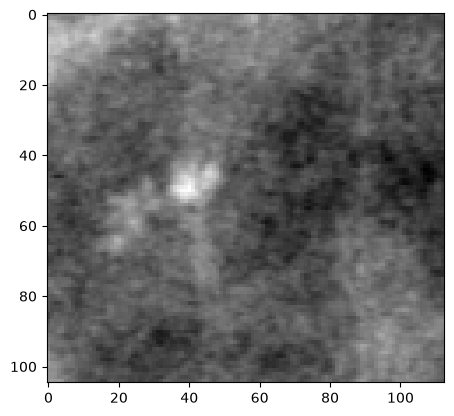

In [8]:
# Display the images

for file in cropped_image[0:10]:
    cropped_images_show = PIL.Image.open(file)
    gray_img= cropped_images_show.convert("L")
    plt.imshow(gray_img, cmap='gray')

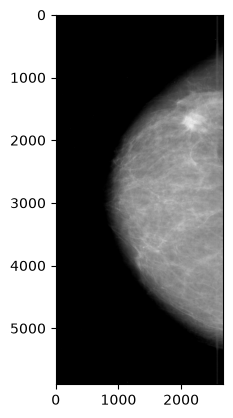

In [9]:
for file in full_image[0:10]:
    full_image_show = PIL.Image.open(file)
    gray_img= full_image_show.convert("L")
    plt.imshow(gray_img, cmap='gray')

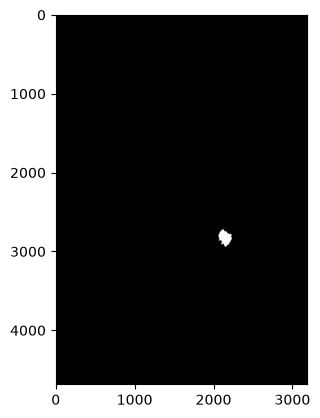

In [10]:
for file in roi_image[0:10]:
    roi_image_show = PIL.Image.open(file)
    gray_img= roi_image_show.convert("L")
    plt.imshow(gray_img, cmap='gray')

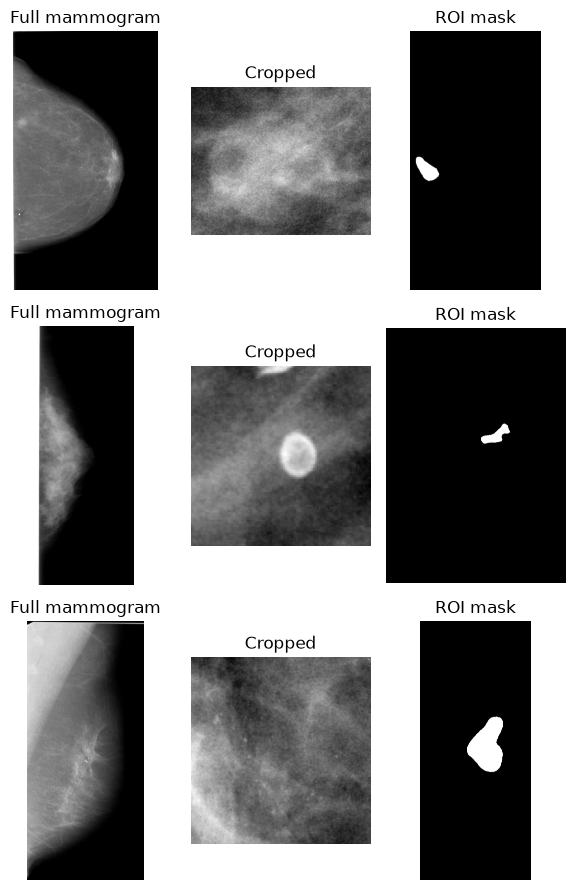

In [11]:
# Display all three mammogram image types
n = 3
fig, axes = plt.subplots(n, 3, figsize=(6, 3 * n))
for i in range(n):
    for col, (series, title) in enumerate([
        (full_image, "Full mammogram"),
        (cropped_image, "Cropped"),
        (roi_image, "ROI mask"),
    ]):
        img = PIL.Image.open(series.iloc[i]).convert("L")
        axes[i, col].imshow(img, cmap="gray")
        axes[i, col].set_title(title)
        axes[i, col].axis("off")
plt.tight_layout()
plt.show()

### Data preprocessing steps
Copy the dataset to `df_dicom`.

In [ ]:
df_dicom = dicom.copy()

In [13]:
# # Drops rows only if the cols contains NA
# df_dicom.isna().sum()
# df_dicom.drop(['BodyPartExamined', 'AccessionNumber', 'Columns', 'ContentDate','ContentTime', 'ConversionType', 'HighBit', 'InstanceNumber', 'PatientSex','PatientBirthDate', 'PhotometricInterpretation',
#                'PixelRepresentation', 'ReferringPhysicianName','Rows','SOPClassUID','SOPInstanceUID', 'SamplesPerPixel', 'SecondaryCaptureDeviceManufacturer', 'SecondaryCaptureDeviceManufacturerModelName', 
#                'SeriesNumber', 'SmallestImagePixelValue', 'SpecificCharacterSet', 'StudyDate','StudyID','StudyTime','InstanceNumber', 'StudyInstanceUID'],axis =1, inplace=True) 

In [14]:
df_dicom

,file_path,image_path,AccessionNumber,BitsAllocated,BitsStored,BodyPartExamined,Columns,ContentDate,ContentTime,ConversionType,...,SecondaryCaptureDeviceManufacturerModelName,SeriesDescription,SeriesInstanceUID,SeriesNumber,SmallestImagePixelValue,SpecificCharacterSet,StudyDate,StudyID,StudyInstanceUID,StudyTime
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.12930...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...,NaN,16,16,BREAST,351,20160426,131732.685,WSD,...,MATLAB,cropped images,1.3.6.1.4.1.9590.100.1.2.129308726812851964007...,1,23078,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.271867287611061855725...,214951.0
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.24838...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...,NaN,16,16,BREAST,3526,20160426,143829.101,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.248386742010678582309...,1,0,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.161516517311681906612...,193426.0
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.26721...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...,NaN,16,16,BREAST,1546,20160503,111956.298,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.267213171011171858918...,1,0,ISO_IR 100,20160807.0,DDSM,1.3.6.1.4.1.9590.100.1.2.291043622711253836701...,161814.0
3,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.38118...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...,NaN,16,16,BREAST,97,20160503,115347.770,WSD,...,MATLAB,cropped images,1.3.6.1.4.1.9590.100.1.2.381187369611524586537...,1,32298,ISO_IR 100,20170829.0,DDSM,1.3.6.1.4.1.9590.100.1.2.335006093711888937440...,180109.0
4,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.38118...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...,NaN,8,8,Left Breast,3104,20160503,115347.770,WSD,...,MATLAB,NaN,1.3.6.1.4.1.9590.100.1.2.381187369611524586537...,1,0,ISO_IR 100,NaN,DDSM,1.3.6.1.4.1.9590.100.1.2.335006093711888937440...,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10232,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.62798...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.627982...,NaN,8,8,BREAST,3744,20160503,134238.422,WSD,...,MATLAB,ROI mask images,1.3.6.1.4.1.9590.100.1.2.627982547125586065005...,1,0,ISO_IR 100,20170906.0,DDSM,1.3.6.1.4.1.9590.100.1.2.310901637111684385906...,91038.0
10233,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.82451...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.824512...,NaN,16,16,BREAST,3316,20160426,123905.617,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.824512568105677732346...,1,0,ISO_IR 100,20161004.0,DDSM,1.3.6.1.4.1.9590.100.1.2.246896536912401556922...,132704.0
10234,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.24759...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.247594...,NaN,16,16,BREAST,2712,20160426,134551.632,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.247594800112988856209...,1,0,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.150339554012064216510...,191922.0
10235,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.28513...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.285138...,NaN,8,8,BREAST,2736,20160426,110906.969,WSD,...,MATLAB,ROI mask images,1.3.6.1.4.1.9590.100.1.2.285138900913160236325...,1,0,ISO_IR 100,20160721.0,DDSM,1.3.6.1.4.1.9590.100.1.2.426769868613284096628...,83526.0


Load `df_mass`, `df_calc`, `df_testMass` and `df_testCalc` and rename the columns.

In [15]:
df_mass = df_mass.rename(columns={'left or right breast': 'left_or_right_breast',
                                    'image view': 'image_view',
                                    'abnormality id': 'abnormality_id',
                                    'abnormality type': 'abnormality_type',
                                    'mass shape': 'mass_shape',
                                    'mass margins': 'mass_margins',
                                    'image file path': 'image_file_path',
                                    'cropped image file path': 'cropped_image_file_path',
                                    'ROI mask file path': 'roi_mask_file_path' })

df_testMass = df_testMass.rename(columns={'left or right breast': 'left_or_right_breast',
                                    'image view': 'image_view',
                                    'abnormality id': 'abnormality_id',
                                    'abnormality type': 'abnormality_type',
                                    'mass shape': 'mass_shape',
                                    'mass margins': 'mass_margins',
                                    'image file path': 'image_file_path',
                                    'cropped image file path': 'cropped_image_file_path',
                                    'ROI mask file path': 'roi_mask_file_path' })

df_calc = df_calc.rename(columns={'breast density': 'breast_density',
                                    'left or right breast': 'left_or_right_breast',
                                    'image view': 'image_view',
                                    'abnormality id': 'abnormality_id',
                                    'abnormality type': 'abnormality_type',
                                    'calc type': 'calc_type',
                                    'calc distribution': 'calc_distribution',
                                    'image file path': 'image_file_path',
                                    'cropped image file path': 'cropped_image_file_path',
                                    'ROI mask file path': 'roi_mask_file_path'})


df_testCalc = df_testCalc.rename(columns={'breast density': 'breast_density',
                                    'left or right breast': 'left_or_right_breast',
                                    'image view': 'image_view',
                                    'abnormality id': 'abnormality_id',
                                    'abnormality type': 'abnormality_type',
                                    'calc type': 'calc_type',
                                    'calc distribution': 'calc_distribution',
                                    'image file path': 'image_file_path',
                                    'cropped image file path': 'cropped_image_file_path',
                                    'ROI mask file path': 'roi_mask_file_path'})


### Mapping the path from `df_dicom['image_path']` to `image_file_path`, `cropped_image_file_ path`, `ROI_mask_file_path` of `df_mass`, `df_calc`

The problem with the current `df_mass` and `df_calc` is that local directory paths of the mammogram images do not directly correspond to usable local file paths. To access the images locally, we have to use `df_dicom` dataset to do a mapping with `df_mass`, `df_calc`, before extracting the paths from `df_dicom['image_path']` to populate in `image_file_path`, `cropped_image_file_ path`, `ROI_mask_file_path` of `df_mass`, `df_calc`.

Each image in `df_dicom` is associated with a SeriesInstanceUID (a unique folder identifier) and a SeriesDescription (indicating whether the image is a full mammogram, a cropped lesion patch, or an ROI mask). We use `df_dicom['SeriesInstanceUID']` and `df_dicom['SeriesDescription']` to look up for them in `df_mass`, `df_calc`. 

For each row in the mass/calc CSVs, the corresponding UID was extracted from its original path string and used to query this lookup for the appropriate image type. Where multiple candidate files matched a given UID, image type pair, following the dataset's naming convention of {Mass|Calc}-{Training|Test}_{patient_id}_{breast side}_{view}[_{abnormality ID}], we reconstruct each case's expected identifier and select the candidate whose stored PatientID matched exactly. Rows for which no valid match could be found were left unresolved rather than assigned an unverified path, and were subsequently excluded from model training.

Same step applies to `df_testMass` and `df_testCalc` datasets.

In [16]:
# Lookup on (SeriesInstanceUID, SeriesDescription) instead of per-row in df_dicom

dicom_valid = dicom.dropna(subset=['SeriesDescription']).copy()
dicom_valid['local_path'] = dicom_valid['image_path'].apply(lambda x: x.replace('CBIS-DDSM/jpeg', image_dir))

path_lookup = {}
for _, r in dicom_valid.iterrows():
    key = (r['SeriesInstanceUID'], r['SeriesDescription'])
    path_lookup.setdefault(key, []).append((r['PatientID'], r['local_path']))

print(f"Lookup built: {len(path_lookup)} (UID, type) keys from {len(dicom_valid)} dicom rows")


Lookup built: 9671 (UID, type) keys from 9671 dicom rows


In [ ]:
# Map raw CSV paths to real local file paths, this section is more sensitive to the image type
def get_uid(path):
    return path.split("/")[2]

# By adding local_full, local_cropped, local_roi columns to `data` 
# resolved from dicom_info.csv via (SeriesInstanceUID, SeriesDescription) so cropped
# images and ROI masks sharing a folder are never swapped
# prefix must match the PatientID prefix used in dicom_info.csv, e.g. "Mass-Training", "Calc-Training", "Mass-Test", "Calc-Test"
# Rows with no match are left as NaN and dropped
def addLocalPathCol(data, prefix):
    data = data.copy()
    col_spec = [
        ('image_file_path', 'full mammogram images', 'local_full'),
        ('cropped_image_file_path', 'cropped images', 'local_cropped'),
        ('roi_mask_file_path', 'ROI mask images', 'local_roi'),
    ]
    for _, _, newcol in col_spec:
        data[newcol] = None

    for idx, row in data.iterrows():
        for srccol, desc, newcol in col_spec:
            uid = get_uid(row[srccol])
            candidates = path_lookup.get((uid, desc))
            if not candidates:
                # Assign as NaN
                continue  

            if newcol == 'local_full':
                expected_pid = f"{prefix}_{row['patient_id']}_{row['left_or_right_breast']}_{row['image_view']}"
            else:
                expected_pid = f"{prefix}_{row['patient_id']}_{row['left_or_right_breast']}_{row['image_view']}_{row['abnormality_id']}"

            matching = [c for c in candidates if c[0] == expected_pid]
            chosen = matching[0] if matching else candidates[0]
            data.at[idx, newcol] = chosen[1]

    return data

df_mass = addLocalPathCol(df_mass, "Mass-Training")
df_calc = addLocalPathCol(df_calc, "Calc-Training")
df_testMass = addLocalPathCol(df_testMass, "Mass-Test")
df_testCalc = addLocalPathCol(df_testCalc, "Calc-Test")

# Check for any NaN rows 
print("\ndf_mass missing local paths:")
print(df_mass[["local_full", "local_cropped", "local_roi"]].isna().sum())
print("\ndf_calc missing local paths:")
print(df_calc[["local_full", "local_cropped", "local_roi"]].isna().sum())
print("\ndf_testMass missing local paths:")
print(df_testMass[["local_full", "local_cropped", "local_roi"]].isna().sum())
print("\ndf_testCalc missing local paths:")
print(df_testCalc[["local_full", "local_cropped", "local_roi"]].isna().sum())



df_mass missing local paths:
local_full       0
local_cropped    0
local_roi        0
dtype: int64

df_calc missing local paths:
local_full       0
local_cropped    2
local_roi        2
dtype: int64

df_testMass missing local paths:
local_full       0
local_cropped    0
local_roi        0
dtype: int64

df_testCalc missing local paths:
local_full       282
local_cropped      0
local_roi        320
dtype: int64


In [18]:
print(df_mass.shape)
print(df_calc.shape)
print(df_testMass.shape)
print(df_testCalc.shape)

(1318, 17)
(1546, 17)
(378, 17)
(326, 17)


From the previous step we can identify:
- `df_calc` has 2 NaN cropped images, 2 NaN ROI images
- `df_testCalc` has 282 NaN full images, 320 NaN ROI images

We will drop the rows for `df_mass` and `df_calc` that contain at least one of the NaN image that cannot be resolved. This is not necessary for test sets as we are not useing that dataset for training.

In [19]:
df_mass = df_mass.dropna(subset=['mass_shape', 'mass_margins'])
df_calc= df_calc.dropna(subset=['calc_type', 'calc_distribution'])
df_testMass = df_testMass.dropna(subset=['mass_margins'])
df_testCalc= df_testCalc.dropna(subset=['calc_type', 'calc_distribution'])


In [ ]:
# Drop rows where the cropped image or ROI mask could not be resolved to a local file 
df_mass = df_mass.dropna(subset=["local_cropped", "local_roi"])
df_calc = df_calc.dropna(subset=["local_cropped", "local_roi"])

print(f"df_mass: {len(df_mass)} rows after dropping")
print(df_mass[["local_full", "local_cropped", "local_roi"]].isna().sum())

print(f"df_calc: {len(df_calc)} rows after dropping")
print(df_calc[["local_full", "local_cropped", "local_roi"]].isna().sum())


df_mass: 1273 rows after dropping
local_full       0
local_cropped    0
local_roi        0
dtype: int64
df_calc: 1149 rows after dropping
local_full       0
local_cropped    0
local_roi        0
dtype: int64


Here we review the number of samples available for each image type. Currently cropped image has the most number of samples available, this will be suitable for CNN training later.

In [23]:
images = pd.DataFrame(df_dicom['SeriesDescription'].value_counts())
images = images.reset_index()
images = images.rename(columns={'SeriesDescription': 'Image Types', 'index':'SeriesDescription'})
images

,Image Types,count
0,cropped images,3567
1,ROI mask images,3247
2,full mammogram images,2857


Combine the datasets.

In [24]:
df = pd.concat([df_mass, df_calc], ignore_index=True)
df_test = pd.concat([df_testMass, df_testCalc], ignore_index=True)

### Label encoding

The original dataset have three types of pathology labels. To avoid confusion, we group and encode all the benign cases as 0 and malignant cases as 1.

In [25]:
label_map = {"MALIGNANT": 1, "BENIGN": 0, "BENIGN_WITHOUT_CALLBACK": 0}
df["labels"] = df["pathology"].map(label_map)
df_test["labels"] = df_test["pathology"].map(label_map)
df = df.dropna(subset=["labels"])
df_test = df_test.dropna(subset=["labels"])

df["labels"] = df["labels"].astype(int)
df_test["labels"] = df_test["labels"].astype(int)

print(f"\nLabel distribution:\n{df['labels'].value_counts()}")
print(df['labels'].unique())
print(f"\nLabel distribution:\n{df_test['labels'].value_counts()}")
print(df_test['labels'].unique())


Label distribution:
labels
0    1254
1    1168
Name: count, dtype: int64
[1 0]

Label distribution:
labels
0    348
1    272
Name: count, dtype: int64
[1 0]


In [29]:
df

,patient_id,breast_density,left_or_right_breast,image_view,abnormality_id,abnormality_type,mass_shape,mass_margins,assessment,pathology,subtlety,image_file_path,cropped_image_file_path,roi_mask_file_path,local_full,local_cropped,local_roi,calc_type,calc_distribution,labels
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.3...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.2...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.2...,NaN,NaN,1
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.3...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.2...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.2...,NaN,NaN,1
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.8...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.4...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.4...,NaN,NaN,0
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.2...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,NaN,NaN,0
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.4...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2417,P_02566,2,RIGHT,MLO,1,calcification,NaN,NaN,5,MALIGNANT,5,Calc-Training_P_02566_RIGHT_MLO/1.3.6.1.4.1.95...,Calc-Training_P_02566_RIGHT_MLO_1/1.3.6.1.4.1....,Calc-Training_P_02566_RIGHT_MLO_1/1.3.6.1.4.1....,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.2...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,AMORPHOUS-PLEOMORPHIC,SEGMENTAL,1
2418,P_02572,2,LEFT,CC,1,calcification,NaN,NaN,0,MALIGNANT,2,Calc-Training_P_02572_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_02572_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_02572_LEFT_CC_1/1.3.6.1.4.1.95...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.3...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,AMORPHOUS,CLUSTERED,1
2419,P_02572,2,LEFT,MLO,1,calcification,NaN,NaN,0,MALIGNANT,2,Calc-Training_P_02572_LEFT_MLO/1.3.6.1.4.1.959...,Calc-Training_P_02572_LEFT_MLO_1/1.3.6.1.4.1.9...,Calc-Training_P_02572_LEFT_MLO_1/1.3.6.1.4.1.9...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.8...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,AMORPHOUS,CLUSTERED,1
2420,P_02584,1,LEFT,CC,1,calcification,NaN,NaN,0,BENIGN,4,Calc-Training_P_02584_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_02584_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_02584_LEFT_CC_1/1.3.6.1.4.1.95...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.1...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.4...,CBISDDSM-AWSAF\jpeg/1.3.6.1.4.1.9590.100.1.2.4...,PLEOMORPHIC,SEGMENTAL,0


In [30]:
# print(df["local_cropped"].iloc[0])
# print(os.path.exists(df["local_cropped"].iloc[0]))


### One hot encoding

Before splitting the dataset, the images and their corresponding labels were pre-processed to prepare them for training and evaluation using the CNN models.

This step iterates through every row of `df`, retrieving the cropped image’s file path from `local_cropped` and its corresponding class from labels. 

Each image is opened using PIL and converted to grayscale with `.convert("L")`. The image is then converted into a NumPy array so that it can be processed numerically.

Next, each image is resized to the dimensions specified by imageSize (224 * 224). The `anti_aliasing`=True` option helps preserve image quality by reducing distortion when the image is resized. `skimage.transform.resize` also produces floating-point pixel values scaled to the range [0, 1]. The processed images and their labels are collected in the images and labels lists.

The categorical labels are then converted into a numerical format. `LabelEncoder` assigns an integer to each class (e.g. 0, 1). The integer encoded class labels were converted into a "two-class" one-hot format using to_categorical. Benign encoded as 0 were represented as [1, 0], while malignant encoded as 1 were represented as [0, 1]. The resulting one-hot encoded label array was converted to the float32 data type.

Finally, the processed image list is converted into the NumPy array `X`, while the one-hot encoded labels are stored in `y`. Therefore, X should have the shape (no. of samples, height, width), while y should have the shape (no. of samples, no. of classes).

In [ ]:
images, labels = [], []

for _, row in df.iterrows():
    path, label = row['local_cropped'], row['labels']

    # Open and decode the image file
    # grayscale = single channel, shape (H, W)
    image = PIL.Image.open(path).convert("L")   
    image = np.array(image)                     

    # Resize to 224 with imageSize
    # shape: (224, 224), values already scaled to [0, 1]
    # using from skimage.transform import resize
    image = resize(image, imageSize, anti_aliasing=True).astype("float32")
    # Convert uint8 [0, 255] pixels to float32 [0, 1]. normalisation step
    # image = np.asarray(image, dtype=np.float32,) / 255.0
    images.append(image)
    labels.append(label)


# One hot encoding
label_encoder = LabelEncoder()
encodedLabels = label_encoder.fit_transform(labels)

X = np.stack(images).astype("float32")
# Converting one-hot labels to binary labels
y = to_categorical(encodedLabels, num_classes=2,).astype("float32")



# no. of samples, w, h
print("X shape:", X.shape)   
# no. of samples,
print("y shape:", y.shape)   
print (y)


X shape: (2422, 224, 224)
y shape: (2422, 2)
[[0. 1.]
 [0. 1.]
 [1. 0.]
 ...
 [0. 1.]
 [1. 0.]
 [1. 0.]]


In [32]:
print("Data type:", X.dtype)
print("Minimum:", X.min())
print("Maximum:", X.max())

Data type: float32
Minimum: 0.0
Maximum: 1.0


## Step 3: Split dataset

- 70% training – for learning features and patterns of the input image data 
- 10% validation (of the train set) – for monitoring the model’s performance, determine the number of epochs and selecting the best hyperparameters
- 20% test set – contains the unseen data excluded from training for final evaluation of the model

`X_main_train` = Train + validation combined

`X_train` = Train

`X_val` = Validation

In [33]:
# 70% train set, 20% test set
# 10% of train --> validation set





# X/y_train_main refers to the train set before splitting between validation-test sets
X_train_main, X_test, y_train_main, y_test = train_test_split(X, y, test_size = 0.20,
                                                              stratify = y, 
                                                              shuffle = True, 
                                                              random_state = 42)

print(f"Training set, no. of samples (70%): {len(X_train_main):}")
print(f"Test set, no. of samples (20%): {len(X_test):}")
print(type(X_train_main[0]))
print(X_train_main[0])

Training set, no. of samples (70%): 1937
Test set, no. of samples (20%): 485
<class 'numpy.ndarray'>
[[0.30210096 0.31966004 0.34554905 ... 0.4135789  0.43761992 0.49230504]
 [0.2916529  0.3123802  0.32163835 ... 0.41479522 0.43387744 0.47810543]
 [0.2800924  0.30629128 0.31127125 ... 0.4258494  0.4402351  0.47251385]
 ...
 [0.30747184 0.2527439  0.31930694 ... 0.18686444 0.19528395 0.21225975]
 [0.2850722  0.26318434 0.32157457 ... 0.1831803  0.19777015 0.1947337 ]
 [0.26442227 0.2904626  0.31472406 ... 0.18089943 0.20235406 0.1667474 ]]


### Get validation set (10% of X_train_main)

In [34]:
X_train, X_val, y_train, y_val = train_test_split(X_train_main, y_train_main, 
                                                  test_size = 0.10,
                                                  stratify = y_train_main.argmax(axis = 1),
                                                  shuffle = True, 
                                                  random_state = 42)

print(f"Training set: {X_train.shape[0]}")
print(f"Validation set: {X_val.shape[0]}")
print(f"Test set: {X_test.shape[0]}")

Training set: 1743
Validation set: 194
Test set: 485


### Normalise pixel values

We conduct validation checks to ensure the train, validation, test sets were pre-processed consistently. Here we scale the image pixel values, which will eventually be the input features `X`, to the range [0, 1]. 

This helps the models to train more stably, converge faster by providing a consistent input scale, while preventing non-standardised or large pixel values from producing unstable weight updates.

In [ ]:

print(f"X_train range: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"X_val range: [{X_val.min():.3f}, {X_val.max():.3f}]")
print(f"X_test range: [{X_test.min():.3f}, {X_test.max():.3f}]")

assert X_train.dtype == np.float32
assert X_val.dtype == np.float32
assert X_test.dtype == np.float32

assert 0.0 <= X_train.min() and X_train.max() <= 1.0
assert 0.0 <= X_val.min() and X_val.max() <= 1.0
assert 0.0 <= X_test.min() and X_test.max() <= 1.0


X_train range: [0.000, 1.000]
X_val range: [0.000, 1.000]
X_test range: [0.000, 1.000]


## Step 4: Establish baseline and its accuracy score

This step examines the distribution of samples across the classes in the main training dataset. 

`label_encoder.classes_ ` retrieves the class label values of 0 and 1 recognised by the label encoder, representing benign and malignant, because we encoded them previously. 

Next, `np.sum(y_train_main, axis=0)` counts the number of samples in each class by adding the values in each column of the one-hot encoded label array. 

We then print each class index, its label, and its total number of samples. 

Based on the results, class 0 (benign) contains 1,003 samples and class 1 (malignant) contains 934 samples. This indicates that the training data is considerably balanced.

In [ ]:
# e.g. array(['BENIGN', 'MALIGNANT']) 
class_names = label_encoder.classes_   

counts = np.sum(y_train_main, axis=0)
print("Samples per class:")
for i, (name, count) in enumerate(zip(class_names, counts)):
    print(f" {i}: {name}: {int(count)}")

Samples per class:
 0: 0: 1003
 1: 1: 934


In [ ]:
n_samples = len(X) # number of images (sample)
n_classes = y.shape[1]
# Imbalance analysis
imbalThreshold = 3.0
imbalRatio = counts.max() / counts.min()

# if class is balanced, use accuracy as metric
accuracy = imbalRatio <= imbalThreshold


print(f"Class imbalance ratio: {imbalRatio:.3f} : 1")
print(f"Threshold: {imbalThreshold} : 1")
print(f"Primary metric selected: {'Accuracy' if accuracy else 'F1-Score'}")
print(f"Sample size (no. of images): {n_samples:}")


Class imbalance ratio: 1.074 : 1
Threshold: 3.0 : 1
Primary metric selected: Accuracy
Sample size (no. of images): 2422


### Final data pre-processing step before CNN training

A CNN model (convnet) takes in and operates on tensor objects as input. In this case, our input image data must be represented as a rank 3 tensor with dimensions of (height, width, channels). To ensure our image arrays are formatted into the expected shape, we restore the channel dimension with `np.expand_dims()`, producing the output of (1743, 224, 224, 1) (no. of samples for training, width, height, grayscale channel).

The one-hot encoded labels were converted into binary values using `np.argmax()`, where [1, 0] became class 0 and [0, 1] became class 1. This produced one binary label for each image.

In [ ]:
# Add the grayscale channel only if it is missing.
if X_train.ndim == 3:
    X_train = X_train[..., np.newaxis]

if X_val.ndim == 3:
    X_val = X_val[..., np.newaxis]

if X_test.ndim == 3:
    X_test = X_test[..., np.newaxis]

# Convert one-hot vectors into binary 0/1 labels.
y_train_bin = np.argmax(y_train, axis=1,).astype("int32")
y_val_bin = np.argmax(y_val, axis=1).astype("int32")
y_test_bin = np.argmax(y_test, axis=1).astype("int32")

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train_bin.shape)
print("First five labels:", y_train_bin[:5])

assert X_train.shape[1:] == (224, 224, 1)
assert X_val.shape[1:] == (224, 224, 1)
assert X_test.shape[1:] == (224, 224, 1)

assert len(X_train) == len(y_train_bin)
assert len(X_val) == len(y_val_bin)
assert len(X_test) == len(y_test_bin)

X_train: (1743, 224, 224, 1)
X_val: (194, 224, 224, 1)
X_test: (485, 224, 224, 1)
y_train: (1743,)
First five labels: [0 1 1 1 1]


### Baseline accruacy: 52%

This forumla calculates the majority class baseline accuracy. Because `y_train_bin` contains only 0 and 1, its mean is equal to the proportion of samples labelled 1.

For example, if 52% of the training samples belong to class 0, a classifier that predicts class 0 for every image would obtain a baseline accuracy of 52%.

In [187]:
baseline = max(np.mean(y_train_bin), 1 - np.mean(y_train_bin))
print(f"Baseline accuracy: {baseline:.3%}")

Baseline accuracy: 51.807%


## Step 5: Build, Compile, Fit Models

1. Define the convnet architecture
2. Compile the model by selecting its loss function, optimizer, and evaluation metrics
3. Create callbacks
4. Fit the model using the training data and provide the validation data for performance monitoring
5. After training, evaluate the final model once on the unseen test dataset.


This code calculates balanced class weights from the training labels. This helps prevent the model from favouring the majority class without changing the number of samples.

In [40]:
weights_array = class_weight.compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_bin),
    y=y_train_bin
)
class_weights = dict(enumerate(weights_array))
print(f"Class weights: {class_weights}")

Class weights: {0: np.float64(0.9651162790697675), 1: np.float64(1.0375)}


Convert the image and label arrays into TensorFlow datasets

In [41]:
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train_bin)).batch(32)
validation_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val_bin)).batch(32)
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test_bin)).batch(32)

#### Model 1 - Base

In [42]:
# No Rescaling(1./255) layer here it was already normalized to [0,1] using skimage.transform.resize(), adding Rescaling here would double-normalize the data.

# input shape (image_height, image_width, image_channels) -> must match original dimension 224, 224
# filters = 32, 64, 128
# kernel size 

inputs = keras.Input(shape=(224, 224, 1))
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(inputs)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation="relu",)(x)
outputs = layers.Dense(1, activation="sigmoid")(x) #single output binary


cnnBaseModel = keras.Model(inputs = inputs, outputs = outputs, name="base_cnn")
cnnBaseModel.summary()

Model: "base_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,616,449 (9.98 MB)

 Trainable params: 2,616,449 (9.98 MB)

 Non-trainable params: 0 (0.00 B)

In [43]:
cnnBaseModel.compile(loss="binary_crossentropy", optimizer="adam",metrics=["accuracy"])
callbacks = [keras.callbacks.ModelCheckpoint(filepath="convnet_from_scratch.keras", save_best_only=True, monitor="val_accuracy")]

# originally val_loss
history = cnnBaseModel.fit(train_dataset, epochs=epochs, validation_data=validation_dataset, class_weight=class_weights, callbacks=callbacks)

Epoch 1/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 31s 529ms/step - accuracy: 0.5221 - loss: 0.6963 - val_accuracy: 0.5155 - val_loss: 0.6928
Epoch 2/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 28s 513ms/step - accuracy: 0.5387 - loss: 0.6924 - val_accuracy: 0.5464 - val_loss: 0.6884
Epoch 3/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 28s 504ms/step - accuracy: 0.5255 - loss: 0.6951 - val_accuracy: 0.4845 - val_loss: 0.6941
Epoch 4/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 27s 499ms/step - accuracy: 0.5227 - loss: 0.6928 - val_accuracy: 0.5000 - val_loss: 0.6970
Epoch 5/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 28s 501ms/step - accuracy: 0.5261 - loss: 0.6905 - val_accuracy: 0.5567 - val_loss: 0.6851
Epoch 6/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 28s 512ms/step - accuracy: 0.5600 - loss: 0.6859 - val_accuracy: 0.5052 - val_loss: 0.6844
Epoch 7/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 40s 500ms/step - accuracy: 0.5582 - loss: 0.6857 - val_accuracy: 0.5825 - val_loss: 0.6752
Epoch 8/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 28s 505ms/step - accuracy: 0.5622 - loss: 0.6808 - val_accu

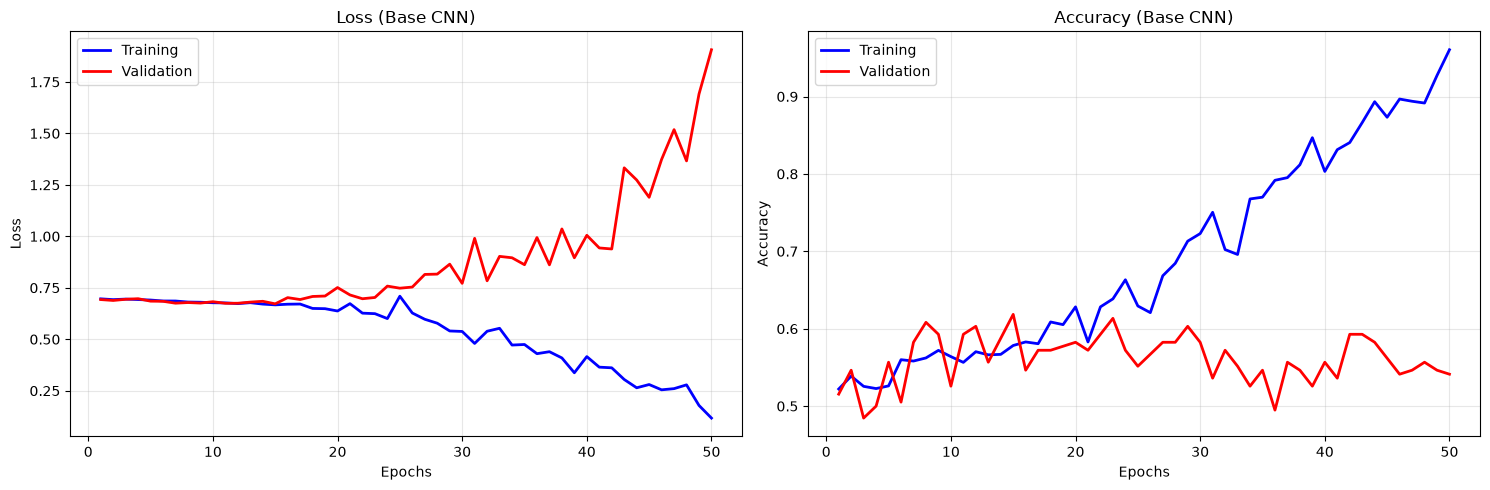

In [ ]:
plotTrainingHistory(history, "Base CNN")

In [45]:
val_loss, val_acc = cnnBaseModel.evaluate(validation_dataset, verbose=0)
print(f"Validation accuracy: {val_acc:.3%}")
print(f"Baseline accuracy:   {baseline:.3%}")
print(f"{'Beats baseline' if val_acc > baseline else 'Does not beat baseline'}")

Validation accuracy: 54.124%
Baseline accuracy:   51.807%
Beats baseline


In [46]:
cnnModel1 = keras.models.load_model("convnet_from_scratch.keras")

printPerfMetrics(cnnModel1, "Base CNN Model")


Base CNN Model
Accuracy: 61.856%
Loss: 0.672
Precision: 61.111%
Recall: 58.511%
F1-score: 59.783%
ROC-AUC: 0.624


#### Model 2: Base + data augmentation

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=seed),
    layers.RandomRotation(factor=0.025, fill_mode="reflect", seed=seed + 1),
    layers.RandomTranslation(height_factor=0.04, width_factor=0.04, fill_mode="reflect", seed=seed + 2),
    layers.RandomZoom(height_factor=0.08, width_factor=0.08, fill_mode="reflect", seed=seed + 3,),
    layers.RandomContrast(factor=0.08, seed=seed + 4),
],name="mammogram_augmentation",)

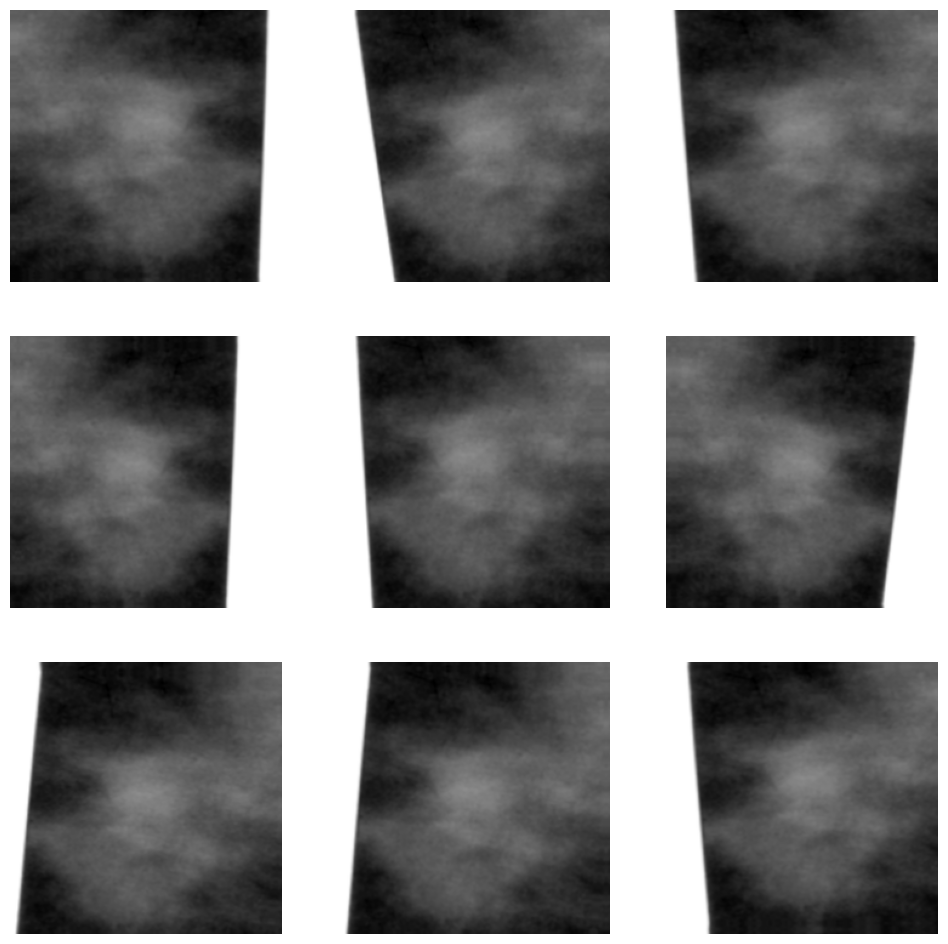

In [189]:
# Sanity check: visualise a few augmented versions of the first cropped
# training image, to confirm the augmentation pipeline looks reasonable
# before training on it.
plt.figure(figsize=(12, 12))
for images, _ in train_dataset.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(augmented_images[0].numpy().squeeze(), cmap="gray")
        plt.axis("off")
plt.show()


In [190]:
inputs = keras.Input(shape=(224, 224, 1))
x = data_augmentation(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation="relu",)(x)
outputs = layers.Dense(1, activation="sigmoid")(x) #single output binary


cnnAugModel2 = keras.Model(inputs = inputs, outputs = outputs, name="aug_cnn")
cnnAugModel2.summary()
cnnAugModel2.compile(loss="binary_crossentropy", optimizer="adam",metrics=["accuracy"])

callbacks2 = [keras.callbacks.ModelCheckpoint(filepath="convnet_from_scratch_with_augment.keras", save_best_only=True, monitor="val_accuracy")]
history2 = cnnAugModel2.fit(train_dataset, epochs=50, validation_data=validation_dataset, class_weight=class_weights, callbacks=callbacks2)


Model: "aug_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mammogram_augmentation          │ (None, 224, 224, 1)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,616,449 (9.98 MB)

 Trainable params: 2,616,449 (9.98 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 13s 203ms/step - accuracy: 0.5055 - loss: 0.6938 - val_accuracy: 0.5155 - val_loss: 0.6931
Epoch 2/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 21s 380ms/step - accuracy: 0.5324 - loss: 0.6941 - val_accuracy: 0.5567 - val_loss: 0.6891
Epoch 3/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 202ms/step - accuracy: 0.5393 - loss: 0.6934 - val_accuracy: 0.4897 - val_loss: 0.6981
Epoch 4/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 202ms/step - accuracy: 0.5370 - loss: 0.6920 - val_accuracy: 0.4948 - val_loss: 0.6965
Epoch 5/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 206ms/step - accuracy: 0.4957 - loss: 0.6937 - val_accuracy: 0.4845 - val_loss: 0.6966
Epoch 6/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 200ms/step - accuracy: 0.5209 - loss: 0.6915 - val_accuracy: 0.5464 - val_loss: 0.6870
Epoch 7/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 208ms/step - accuracy: 0.5473 - loss: 0.6899 - val_accuracy: 0.4948 - val_loss: 0.6913
Epoch 8/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 209ms/step - accuracy: 0.5181 - loss: 0.6906 - val_accu

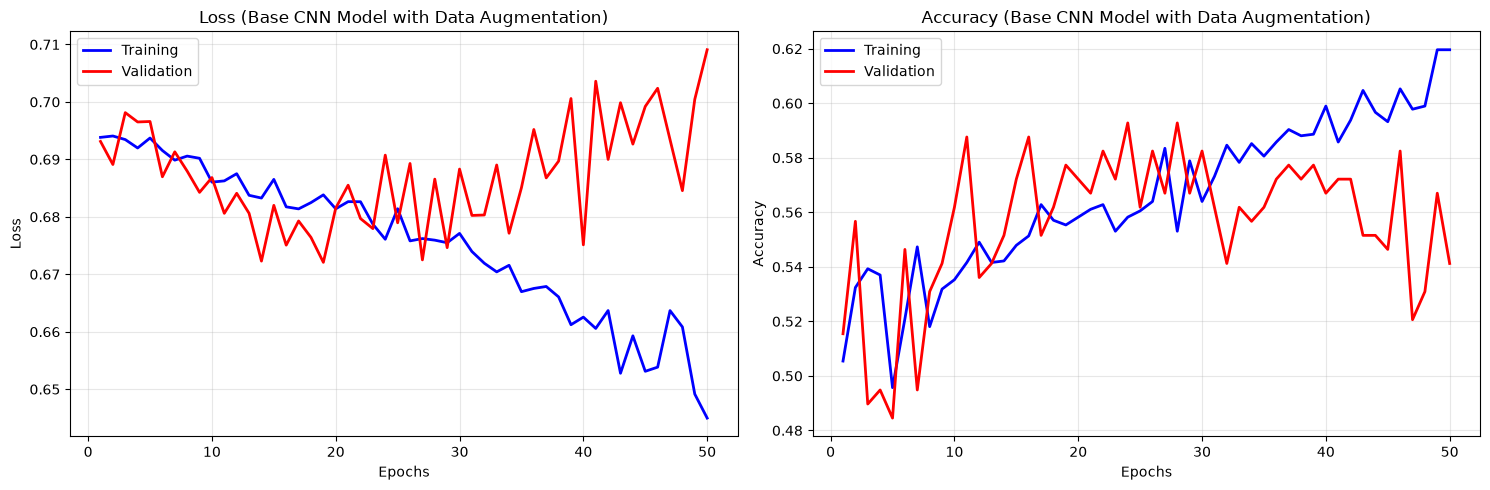

In [191]:
plotTrainingHistory(history2, "Base CNN Model with Data Augmentation")


In [192]:
val_loss, val_acc = cnnAugModel2.evaluate(validation_dataset, verbose=0)
print(f"Validation accuracy: {val_acc:.3%}")
print(f"Baseline accuracy:   {baseline:.3%}")
print(f"{'Beats baseline' if val_acc > baseline else 'Does not beat baseline'}")

Validation accuracy: 54.124%
Baseline accuracy:   51.807%
Beats baseline


In [193]:
cnnModel2 = keras.models.load_model("convnet_from_scratch_with_augment.keras")

printPerfMetrics(cnnModel2, "Base CNN Model with Data Augmentation")


=============== Base CNN Model with Data Augmentation ===============
Accuracy: 59.278%
Loss: 0.691
Precision: 56.198%
Recall/Sensitivity: 72.340%
F1-score: 63.256%
ROC-AUC: 0.5690


{'loss': 0.6907367706298828,
 'accuracy': 0.5927835051546392,
 'precision': 0.5619834710743802,
 'recall': 0.723404255319149,
 'f1': 0.6325581395348837,
 'auc': 0.5690425531914893,
 'probabilities': array([0.6225985 , 0.4501854 , 0.45685583, 0.5264981 , 0.6484655 ,
        0.46952927, 0.39216805, 0.57997775, 0.582445  , 0.4308393 ,
        0.52952623, 0.62411433, 0.55272293, 0.44409892, 0.31760508,
        0.51384544, 0.51958215, 0.42925593, 0.5710726 , 0.5697046 ,
        0.40341827, 0.52752316, 0.4089798 , 0.5783208 , 0.4942229 ,
        0.6553723 , 0.594591  , 0.5972886 , 0.59802896, 0.47628537,
        0.45756325, 0.2812749 , 0.32449463, 0.41785142, 0.39499122,
        0.45187503, 0.78681934, 0.44865176, 0.49165094, 0.65419245,
        0.65381813, 0.5842629 , 0.5820725 , 0.5672935 , 0.5672123 ,
        0.518616  , 0.44374475, 0.6387514 , 0.6576149 , 0.5702165 ,
        0.60367405, 0.43146202, 0.65342903, 0.629935  , 0.31341743,
        0.6094557 , 0.66821355, 0.4828488 , 0.6929467 

#### Model 3: L2 & Regularisation

In [ ]:
# Small L2 regularisation value because Model 2 is already learning slowly
l2_reg = keras.regularizers.l2(0.00001)

inputs = keras.Input(shape=(224, 224, 1))
x = data_augmentation(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu", kernel_regularizer=l2_reg)(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu", kernel_regularizer=l2_reg)(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation="relu",)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
# Apply dropout before the final classifier
# x = layers.Dropout(0.25)(x)

cnnl2RegModel = keras.Model(inputs=inputs, outputs=outputs, name = "l2reg_cnn")
cnnl2RegModel.summary()
cnnl2RegModel.compile(loss="binary_crossentropy", optimizer="adam",metrics=["accuracy"])

callbacks3 = [keras.callbacks.ModelCheckpoint(filepath="convnet_with_dropout_regularisation.keras", monitor="val_accuracy", save_best_only=True)]
    
history3 = cnnl2RegModel.fit(train_dataset, epochs=50, validation_data=validation_dataset, class_weight=class_weights, callbacks=callbacks3)


Model: "l2reg_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mammogram_augmentation          │ (None, 224, 224, 1)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,616,449 (9.98 MB)

 Trainable params: 2,616,449 (9.98 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 32s 534ms/step - accuracy: 0.5278 - loss: 0.7022 - val_accuracy: 0.4897 - val_loss: 0.7017
Epoch 2/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 41s 534ms/step - accuracy: 0.5164 - loss: 0.6961 - val_accuracy: 0.4845 - val_loss: 0.6948
Epoch 3/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 28s 514ms/step - accuracy: 0.4928 - loss: 0.6947 - val_accuracy: 0.5155 - val_loss: 0.6945
Epoch 4/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 24s 447ms/step - accuracy: 0.5118 - loss: 0.6945 - val_accuracy: 0.5155 - val_loss: 0.6943
Epoch 5/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 17s 299ms/step - accuracy: 0.5164 - loss: 0.6943 - val_accuracy: 0.5155 - val_loss: 0.6942
Epoch 6/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 29s 535ms/step - accuracy: 0.5100 - loss: 0.6944 - val_accuracy: 0.5155 - val_loss: 0.6941
Epoch 7/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 30s 538ms/step - accuracy: 0.5089 - loss: 0.6942 - val_accuracy: 0.5155 - val_loss: 0.6940
Epoch 8/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 29s 535ms/step - accuracy: 0.5135 - loss: 0.6942 - val_accu

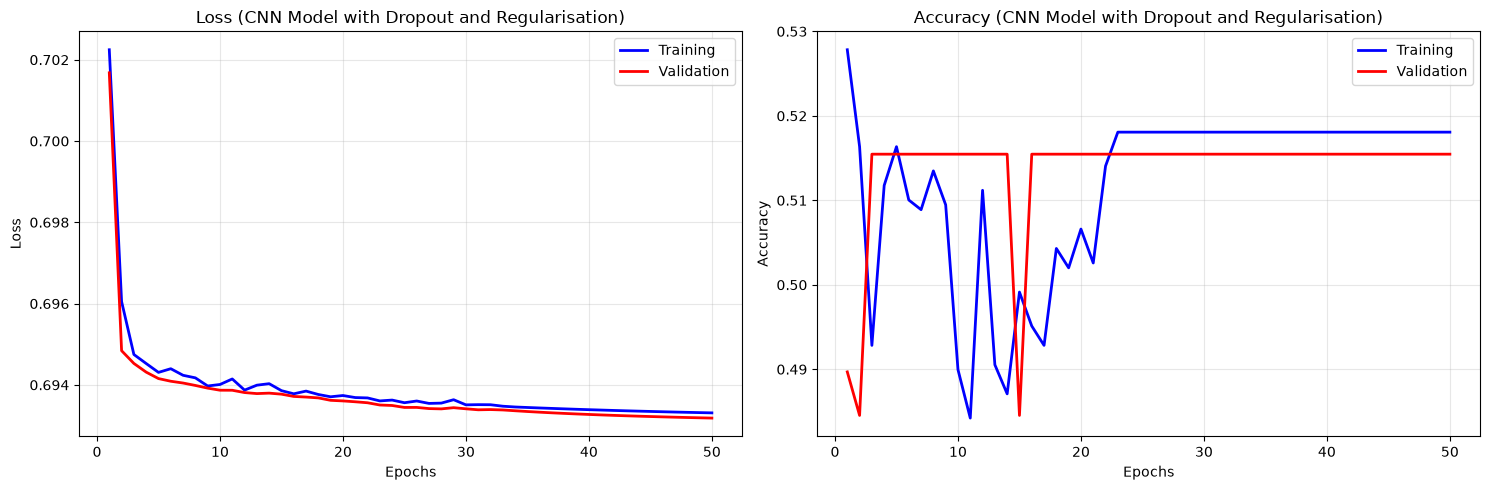

In [56]:
plotTrainingHistory(history3, "CNN Model with Dropout and Regularisation")


In [57]:
val_loss, val_acc = cnnl2RegModel.evaluate(validation_dataset, verbose=0)
print(f"Validation accuracy: {val_acc:.3%}")
print(f"Baseline accuracy: {baseline:.3%}")
print(f"{'Beats baseline' if val_acc > baseline else 'Does not beat baseline'}")

Validation accuracy: 51.546%
Baseline accuracy: 51.807%
Does not beat baseline


In [58]:
cnnModel3 = keras.models.load_model("convnet_with_dropout_regularisation.keras")

printPerfMetrics(cnnModel3, "CNN Model with Dropout and Regularisation")


CNN Model with Dropout and Regularisation
Accuracy: 51.546%
Loss: 0.695
Precision: 0.000%
Recall: 0.000%
F1-score: 0.000%
ROC-AUC: 0.508


#### Model 4: Hyperparameter tuning

Use `hyperband()` to search for the best hyperparameters search to identify the best hyperparameter combination defined in `hpTunedCNN` with only training duration of epochs 30.

In [ ]:
def hpTunedCNN(hp):
    keras.backend.clear_session()

    # Hyperparameters to search
    dense_units = hp.Choice("dense_units", values=[32, 64, 128])

    dropout_rate = hp.Choice("dropout_rate", values=[0.25, 0.40, 0.50])

    l2_strength = hp.Choice("l2_strength", values=[0.0, 1e-5, 1e-4])

    learning_rate = hp.Choice("learning_rate", values=[1e-4, 3e-4, 1e-3])

    l2_regularizer = keras.regularizers.l2(l2_strength)

    inputs = keras.Input(shape=(224, 224, 1))
    # Create an independent augmentation pipeline for each trial
    augmentation = keras.models.clone_model(data_augmentation)
    x = augmentation(inputs)
    x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
    x = layers.Flatten()(x)
    x = layers.Dense(units=dense_units, activation="relu", kernel_regularizer=l2_regularizer)(x)
    x = layers.Dropout(rate=dropout_rate)(x)
    outputs = layers.Dense(1, activation="sigmoid", kernel_regularizer=l2_regularizer)(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="tuned_cnn",)

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate,), 
                         loss="binary_crossentropy",
                         metrics=["accuracy"])

    return model

tuner = kt.Hyperband(
    hypermodel=hpTunedCNN,
    objective=kt.Objective(
        "val_accuracy",
        direction="max",
    ),
    max_epochs=30,
    factor=3,
    directory= r"C:\Users\Naying\OneDrive\FYP\FYP HP", # remember to replace this
    project_name="cnn_hyperband",
)

tuner.search_space_summary()

Reloading Tuner from C:\Users\Naying\OneDrive\FYP\FYP HP\cnn_hyperband\tuner0.json
Search space summary
Default search space size: 4
dense_units (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128], 'ordered': True}
dropout_rate (Choice)
{'default': 0.25, 'conditions': [], 'values': [0.25, 0.4, 0.5], 'ordered': True}
l2_strength (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 1e-05, 0.0001], 'ordered': True}
learning_rate (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.0003, 0.001], 'ordered': True}


Search for the best hyperparameters & Display the best hyperparameters

In [ ]:
tunerEarlyStopping = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=5,
    restore_best_weights=True,
)

tuner.search(
    train_dataset,
    validation_data=validation_dataset,
    epochs=30,
    class_weight=class_weights,
    callbacks=[tunerEarlyStopping],
)

bestHp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best hyperparameters")
print("Dense units:  ", bestHp.get("dense_units"))
print("Dropout rate:", bestHp.get("dropout_rate"))
print("L2 strength: ", bestHp.get("l2_strength"))
print("Learning rate:", bestHp.get("learning_rate"))

Trial 84 Complete [00h 01m 48s]
val_accuracy: 0.561855673789978

Best val_accuracy So Far: 0.6288659572601318
Total elapsed time: 01h 50m 16s
Best hyperparameters
Dense units:   64
Dropout rate: 0.25
L2 strength:  1e-05
Learning rate: 0.0001


Retrieve the best tuned model & Evaluate it on validation data:

In [ ]:
opCNNmodel = tuner.get_best_models(num_models=1)[0]

opCNNmodel.summary()

printPerfMetrics(opCNNmodel, "CNN with Tuned Hyperparameters",)

Model: "tuned_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mammogram_augmentation          │ (None, 224, 224, 1)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,616,449 (9.98 MB)

 Trainable params: 2,616,449 (9.98 MB)

 Non-trainable params: 0 (0.00 B)


CNN with Tuned Hyperparameters
Accuracy: 62.887%
Loss: 0.653
Precision: 57.857%
Recall: 86.170%
F1-score: 69.231%
ROC-AUC: 0.661


### Re-train the model, this time using the selected best hyperparameters and `X_train_main`, `X_test`

Find best epoch first, which is 8.

In [74]:
keras.backend.clear_session()
keras.utils.set_random_seed(seed)

epochSelectionModel = tuner.hypermodel.build(
    bestHp
)

epochSelectionCallbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=7,
        restore_best_weights=True,
    )
]

epochSelectionHistory = epochSelectionModel.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=50,
    class_weight=class_weights,
    callbacks=epochSelectionCallbacks,
    verbose=1,
)

# Find the epoch with the highest validation accuracy.
validationAccuracy = np.asarray(
    epochSelectionHistory.history["val_accuracy"]
)

bestEpochs = int(np.argmax(validationAccuracy) + 1)

print("Best validation accuracy:", validationAccuracy.max())
print("Best number of epochs:", bestEpochs)

Epoch 1/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 12s 202ms/step - accuracy: 0.5158 - loss: 0.6945 - val_accuracy: 0.4845 - val_loss: 0.6953
Epoch 2/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 200ms/step - accuracy: 0.5307 - loss: 0.6941 - val_accuracy: 0.4897 - val_loss: 0.6949
Epoch 3/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 12s 217ms/step - accuracy: 0.5192 - loss: 0.6935 - val_accuracy: 0.4897 - val_loss: 0.6960
Epoch 4/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 12s 211ms/step - accuracy: 0.5261 - loss: 0.6909 - val_accuracy: 0.5000 - val_loss: 0.7070
Epoch 5/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 12s 216ms/step - accuracy: 0.5232 - loss: 0.6927 - val_accuracy: 0.5412 - val_loss: 0.6852
Epoch 6/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 207ms/step - accuracy: 0.5232 - loss: 0.6878 - val_accuracy: 0.5361 - val_loss: 0.6835
Epoch 7/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 201ms/step - accuracy: 0.5468 - loss: 0.6838 - val_accuracy: 0.5773 - val_loss: 0.6787
Epoch 8/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 203ms/step - accuracy: 0.5571 - loss: 0.6843 - val_accu

Prep X_train_main

In [ ]:
X_final_train = X_train_main.astype("float32")

# Add the grayscale channel dimension if missing
if X_final_train.ndim == 3:
    X_final_train = X_final_train[..., np.newaxis]

# Convert one-hot labels into binary labels
y_final_train = np.argmax(y_train_main, axis=1).astype("int32")

print("Final training images:", X_final_train.shape)
print("Final training labels:", y_final_train.shape)
print("Final training range:", X_final_train.min(), "to", X_final_train.max())

assert X_final_train.shape[1:] == (224, 224, 1)
assert len(X_final_train) == len(y_final_train)
assert X_final_train.dtype == np.float32

Final training images: (1937, 224, 224, 1)
Final training labels: (1937,)
Final training range: 0.0 to 1.0


Recalculate class weights because no we are using train + validation sets

In [76]:
finalClasses = np.unique(y_final_train)

finalWeightsArray = class_weight.compute_class_weight(
    class_weight="balanced",
    classes=finalClasses,
    y=y_final_train,
)

finalClassWeights = {
    int(label): float(weight)
    for label, weight in zip(
        finalClasses,
        finalWeightsArray,
    )
}

print("Final class weights:", finalClassWeights)

Final class weights: {0: 0.9656031904287139, 1: 1.0369379014989293}


Convert the final training dataset into TensorFlow datasets

In [77]:
finalTrainingDataset = (
    tf.data.Dataset
    .from_tensor_slices(
        (X_final_train, y_final_train)
    )
    .shuffle(
        buffer_size=len(X_final_train),
        seed=seed,
        reshuffle_each_iteration=True,
    )
    .batch(batchSize)
    .prefetch(tf.data.AUTOTUNE)
)

Re-build and fit final model with the optimised epoch and class weight

In [ ]:
keras.backend.clear_session()
keras.utils.set_random_seed(seed)

finalTunedModel = tuner.hypermodel.build(bestHp)

finalTunedModel.summary()

finalHistory = finalTunedModel.fit(finalTrainingDataset, epochs=bestEpochs, class_weight=finalClassWeights)

Model: "tuned_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mammogram_augmentation          │ (None, 224, 224, 1)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,616,449 (9.98 MB)

 Trainable params: 2,616,449 (9.98 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
61/61 ━━━━━━━━━━━━━━━━━━━━ 13s 196ms/step - accuracy: 0.4837 - loss: 0.6944
Epoch 2/8
61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 194ms/step - accuracy: 0.4739 - loss: 0.6946
Epoch 3/8
61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 196ms/step - accuracy: 0.4987 - loss: 0.6941
Epoch 4/8
61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 195ms/step - accuracy: 0.5059 - loss: 0.6939
Epoch 5/8
61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 196ms/step - accuracy: 0.5106 - loss: 0.6928
Epoch 6/8
61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 195ms/step - accuracy: 0.5204 - loss: 0.6914
Epoch 7/8
61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 195ms/step - accuracy: 0.5266 - loss: 0.6903
Epoch 8/8
61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 196ms/step - accuracy: 0.5426 - loss: 0.6859


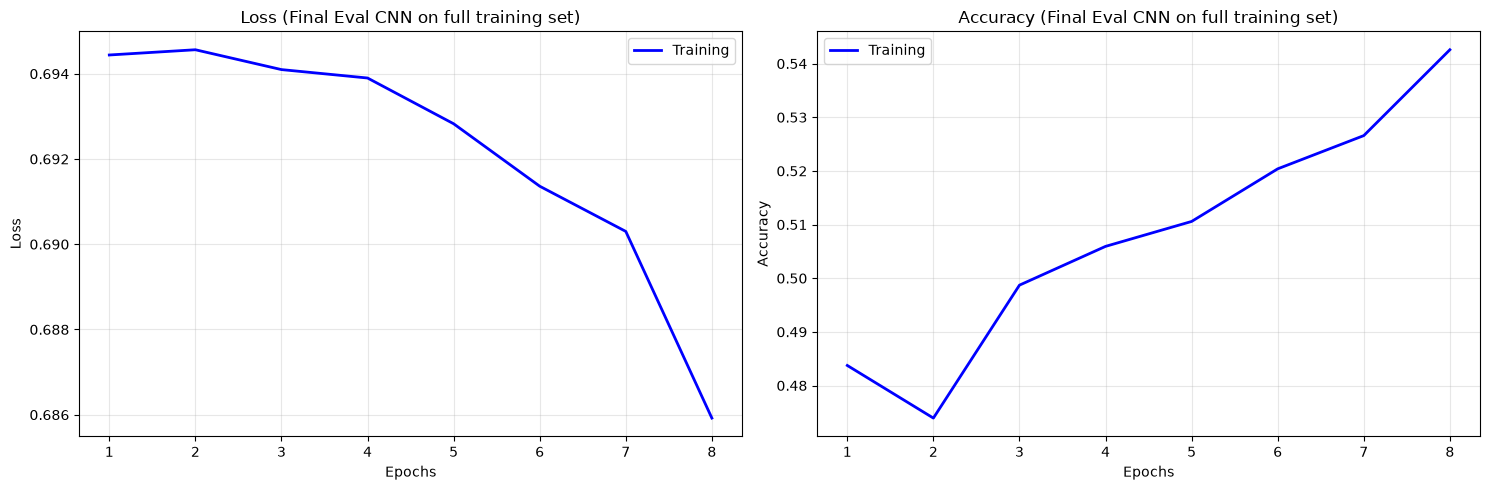

In [79]:
plotTrainingHistory(
    finalHistory,
    "Final Eval CNN on full training set",
)

In [ ]:
finalTunedModel.save("final_tuned_cnn.keras")

Evaluate once on `X_test`

The existing test_dataset contains X_test and y_test_bin:

In [81]:
testLoss, testAccuracy = finalTunedModel.evaluate(
    test_dataset,
    verbose=0,
)

testProbabilities = finalTunedModel.predict(
    test_dataset,
    verbose=0,
).reshape(-1)

testPredictions = (
    testProbabilities >= 0.5
).astype("int32")

In [102]:
testResults = printPerfMetrics(
    finalTunedModel,
    "Final Evaluation of Optimised CNN Model with splitted test set",
    dataset=test_dataset,
    y_true=y_test_bin,
)


=============== Final Evaluation of Optimised CNN Model with splitted test set ===============
Accuracy: 58.144%
Loss: 0.684
Precision: 58.289%
Recall/Sensitivity: 46.581%
F1-score: 51.781%
ROC-AUC: 0.5832


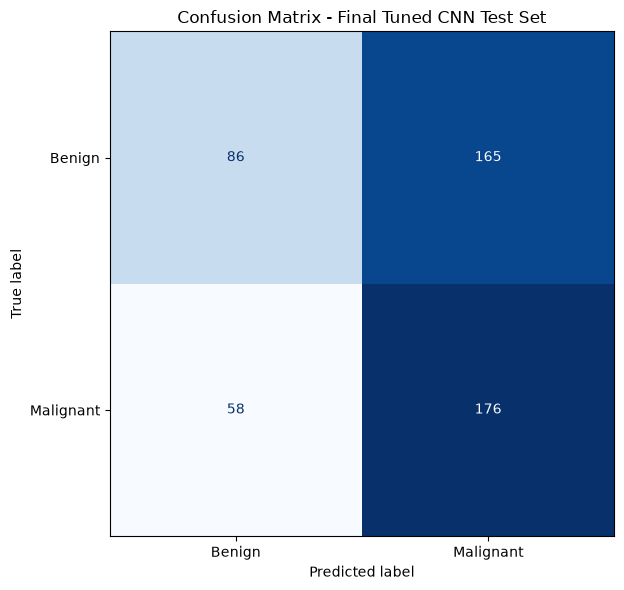

In [ ]:
testConfusionMatrix = plotConfusionMatrix(y_test_bin, testPredictions, title="Confusion Matrix - Final Tuned CNN Test Set")

In [84]:
finalTunedModel.fit(finalTrainingDataset)

61/61 ━━━━━━━━━━━━━━━━━━━━ 13s 195ms/step - accuracy: 0.5467 - loss: 0.6859


In [85]:
finalTunedModel.evaluate(test_dataset)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.5814 - loss: 0.6837


[0.6837460994720459, 0.5814433097839355]

### Re-train the model, this time using the selected best hyperparameters and `df_test`

Repeat the previous pre-processing steps on df_test

In [ ]:
# Create a clean test dataframe
df_testSet = (
    df_test
    .dropna(subset=["local_cropped", "labels"])
    .reset_index(drop=True)
)

assert len(df_testSet) > 0, "df_testSet contains no usable rows."

# Check that every image path exists
missingFiles = ~df_testSet["local_cropped"].map(os.path.isfile)

print("Test rows:", len(df_testSet))
print("Missing files:", missingFiles.sum())

assert not missingFiles.any(), ("Some files in df_testSet['local_cropped'] do not exist.")

Test rows: 620
Missing files: 0


In [92]:
testImages = []

for imagePath in df_testSet["local_cropped"]:
    image = PIL.Image.open(imagePath).convert("L")
    image = np.asarray(image)

    # Same normalising step
    image = resize(
        image,
        imageSize,
        anti_aliasing=True,
    ).astype("float32")

    testImages.append(image)

X_df_test = np.stack(testImages).astype("float32")

# Add the grayscale channel dimension.
if X_df_test.ndim == 3:
    X_df_test = X_df_test[..., np.newaxis]

y_df_test = df_testSet["labels"].to_numpy(
    dtype="int32"
)

print("X_df_test shape:", X_df_test.shape)
print("y_df_test shape:", y_df_test.shape)
print(
    "Pixel range:",
    X_df_test.min(),
    X_df_test.max(),
)

assert X_df_test.shape[1:] == (224, 224, 1)
assert len(X_df_test) == len(y_df_test)
assert X_df_test.dtype == np.float32
assert 0.0 <= X_df_test.min()
assert X_df_test.max() <= 1.0

X_df_test shape: (620, 224, 224, 1)
y_df_test shape: (620,)
Pixel range: 0.0 1.0


In [ ]:
dfTestDataset = tf.data.Dataset.from_tensor_slices((X_df_test, y_df_test)).batch(batchSize)

In [94]:
dfTestResults = finalTunedModel.evaluate(
    dfTestDataset,
    verbose=0,
    return_dict=True,
)

print("\nFinal model on df_test")

for metricName, metricValue in dfTestResults.items():
    print(f"{metricName}: {metricValue:.4f}")


Final model on df_test
accuracy: 0.5484
loss: 0.6864


In [95]:
dfTestProbabilities = finalTunedModel.predict(
    dfTestDataset,
    verbose=0,
).reshape(-1)

dfTestPredictions = (
    dfTestProbabilities >= 0.5
).astype("int32")

In [103]:
dfTestResults = printPerfMetrics(
    finalTunedModel,
    "Final Evaluation of Optimised CNN Model with df_test",
    dataset=dfTestDataset,
    y_true=y_df_test,
)


=============== Final Evaluation of Optimised CNN Model with df_test ===============
Accuracy: 54.839%
Loss: 0.686
Precision: 48.571%
Recall/Sensitivity: 50.000%
F1-score: 49.275%
ROC-AUC: 0.5534


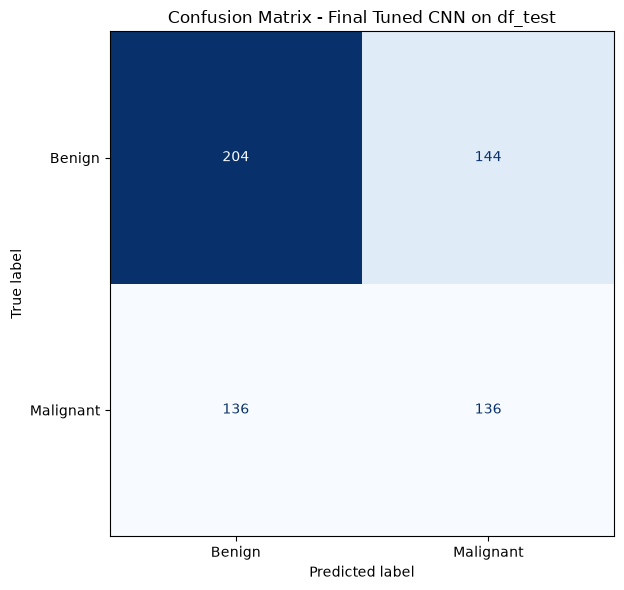

In [100]:
dfTestConfusionMatrix = plotConfusionMatrix(y_df_test, dfTestPredictions, title="Confusion Matrix - Final Tuned CNN on df_test")

## Step 6: Building Resnet50

First, create a ResNet50 base for transfer learning using weights learned from ImageNet. Use `include_top=false` to remove original classification layers allowing a new binary classifier to be added

In [194]:
# function for building the ResNet50 architecture

def baseResNet50():

    baseRN50 = keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3),
        name="base_resnet50",
    )
    return baseRN50

Build a frozen feature extractor

In [195]:
keras.backend.clear_session()
keras.utils.set_random_seed(seed)

resnetBase = baseResNet50()

# Freeze the complete pretrained convolutional base.
resnetBase.trainable = False

Create tensor object

In [196]:
resnetTrainDataset = (
    tf.data.Dataset.from_tensor_slices(
        (X_train, y_train_bin)
    )
    .shuffle(
        buffer_size=len(X_train),
        seed=seed,
        reshuffle_each_iteration=True,
    )
    .batch(batchSize)
    .prefetch(tf.data.AUTOTUNE)
)

resnetValidationDataset = (
    tf.data.Dataset.from_tensor_slices(
        (X_val, y_val_bin)
    )
    .batch(batchSize)
    .prefetch(tf.data.AUTOTUNE)
)

Build the new classifier on top:

In [197]:
inputs = keras.Input(shape=(224, 224, 1))
x = data_augmentation(inputs) # include the previous data augmentation layer
# Convert grayscale to three identical channels.
x = layers.Concatenate(axis=-1)([x, x, x])
# ResNet50 preprocess_input expects approximately [0, 255].
x = layers.Rescaling(255.0)(x)
x = preprocess_input(x)

# For extracting features
# training=False is important because ResNet50 contains batch normalisation layers
x = resnetBase(x, training=False)

# Convert the feature maps into a feature vector
x = layers.GlobalAveragePooling2D()(x)
# Regularise the new classifier.
x = layers.Dropout(0.5)(x)
# New binary classifier
outputs = layers.Dense(1, activation="sigmoid")(x)

resnetFeatureModel = keras.Model(inputs=inputs, outputs=outputs, name="resnet50_feature_extract")

print("ResNet50 trainable:", resnetBase.trainable)

resnetFeatureModel.summary()

resnetFeatureModel.compile(optimizer="rmsprop",
                           loss="binary_crossentropy",
                           metrics=["accuracy"])

ResNet50 trainable: False


Model: "resnet50_feature_extract"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mammogram_augmenta… │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 224, 224,  │          0 │ mammogram_augmen… │
│ (Concatenate)       │ 3)                │            │ mammogram_augmen… │
│                     │                   │            │ mammogram_augmen… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ concatenate[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ base_resnet50       │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ base_resnet50[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │      2,049 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 26s 433ms/step - accuracy: 0.5559 - loss: 0.7944 - val_accuracy: 0.6443 - val_loss: 0.6415
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 43s 788ms/step - accuracy: 0.5932 - loss: 0.6946 - val_accuracy: 0.6649 - val_loss: 0.6228
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 23s 412ms/step - accuracy: 0.6179 - loss: 0.6613 - val_accuracy: 0.6856 - val_loss: 0.6013
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 23s 415ms/step - accuracy: 0.6288 - loss: 0.6583 - val_accuracy: 0.6856 - val_loss: 0.5898
Epoch 5/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 23s 424ms/step - accuracy: 0.6627 - loss: 0.6140 - val_accuracy: 0.6134 - val_loss: 0.6945
Epoch 6/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 42s 766ms/step - accuracy: 0.6363 - loss: 0.6335 - val_accuracy: 0.6701 - val_loss: 0.5845
Epoch 7/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 24s 446ms/step - accuracy: 0.6627 - loss: 0.6199 - val_accuracy: 0.6856 - val_loss: 0.5814
Epoch 8/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 31s 567ms/step - accuracy: 0.6690 - loss: 0.6044 - val_accu

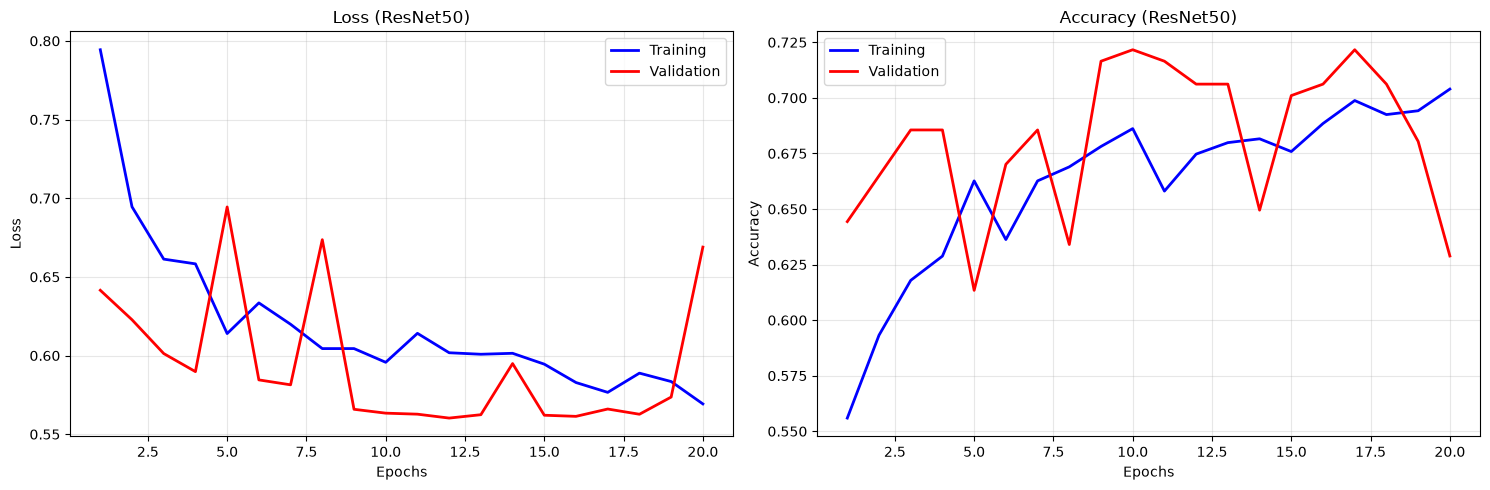


=============== ResNet50 ===============
Accuracy: 62.887%
Loss: 0.669
Precision: 84.375%
Recall/Sensitivity: 28.723%
F1-score: 42.857%
ROC-AUC: 0.7665


In [199]:
base_resnetCallbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="resnet50_feature_extract.keras",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
    )
]

base_resnetHistory = (resnetFeatureModel.fit(resnetTrainDataset,
                                                   validation_data=validation_dataset,
                                                   epochs=20,
                                                   class_weight=class_weights,
                                                   callbacks=base_resnetCallbacks))

plotTrainingHistory(base_resnetHistory, title="ResNet50")

featureExtractionResults = printPerfMetrics(resnetFeatureModel, "ResNet50", dataset=validation_dataset, y_true=y_val_bin)

Load the best feature extraction pre-trained model with learned weights

In [ ]:
# load the trained checkpoint from earlier 
# The frozen pretrained ResNet50 weights.
# The trained binary classification head.
# The weights from the epoch with the lowest validation loss.
# The architecture and compile configuration that were used when it was saved.

best_base_resnet = keras.models.load_model("resnet50_feature_extract.keras")

# contains the pretrained resnet50 convolutional layers
baseConvLayers = best_base_resnet.get_layer("base_resnet50")

print("ResNet50 frozen:", not baseConvLayers.trainable)
print("Trainable ResNet50 weights:", len(baseConvLayers.trainable_weights))

ResNet50 frozen: True
Trainable ResNet50 weights: 0


Evaluate on validation data

In [ ]:
resnetValidationResults = printPerfMetrics(
    best_base_resnet,
    "ResNet50 Frozen Feature Extraction - validation set",
    dataset=validation_dataset,
    y_true=y_val_bin,
)


=============== ResNet50 Frozen Feature Extraction - validation set ===============
Accuracy: 71.649%
Loss: 0.563
Precision: 78.261%
Recall/Sensitivity: 57.447%
F1-score: 66.258%
ROC-AUC: 0.7893


Final evaluation on X_test

In [ ]:
resnetTestResults = printPerfMetrics(
    best_base_resnet,
    "ResNet50 Frozen Feature Extractor - Test set",
    dataset=test_dataset,
    y_true=y_test_bin,
)


=============== ResNet50 Frozen Feature Extractor - Test set ===============
Accuracy: 67.216%
Loss: 0.594
Precision: 72.189%
Recall/Sensitivity: 52.137%
F1-score: 60.546%
ROC-AUC: 0.7536


### ResNet50 on `df_test`


=============== ResNet50 Frozen Feature Extraction - df_test ===============
Accuracy: 66.452%
Loss: 0.611
Precision: 64.035%
Recall/Sensitivity: 53.676%
F1-score: 58.400%
ROC-AUC: 0.7063


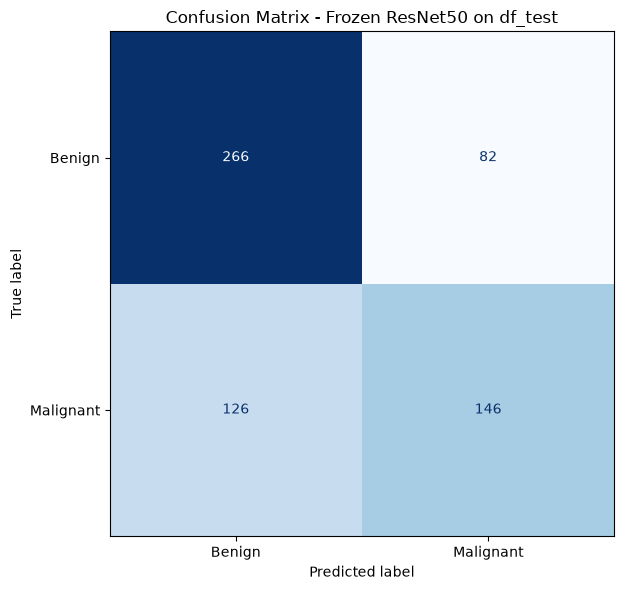

array([[266,  82],
       [126, 146]])

In [ ]:
resnetDfTestResults = printPerfMetrics(
    best_base_resnet,
    "ResNet50 Frozen Feature Extraction - df_test",
    dataset=dfTestDataset,
    y_true=y_df_test,
)
plotConfusionMatrix(
    y_df_test,
    resnetDfTestResults["predictions"],
    title=("Confusion Matrix - Frozen ResNet50 on df_test")
)

### ResNet50 with best hyperparameters

In [ ]:
inputs = keras.Input(shape=(224, 224, 1))

x = data_augmentation(inputs)
x = layers.Concatenate(axis=-1)([x, x, x])
x = layers.Rescaling(255.0)(x)
x = preprocess_input(x)
x = resnetBase(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(units=bestHp.get("dense_units"), activation="relu", kernel_regularizer=keras.regularizers.l2(bestHp.get("l2_strength")))(x)
x = layers.Dropout(bestHp.get("dropout_rate"))(x)
outputs = layers.Dense(1, activation="sigmoid",)(x)

resnet_hpModel = keras.Model(inputs=inputs, outputs=outputs, name="resnet50_op_hyperparameters",)

print("ResNet50 trainable:", resnetBase.trainable)

resnet_hpModel.summary()

resnet_hpModel.compile(optimizer=keras.optimizers.RMSprop(learning_rate=bestHp.get("learning_rate")), 
                      loss="binary_crossentropy",
                      metrics=["accuracy"])



ResNet50 trainable: False


Model: "resnet50_op_hyperparameters"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mammogram_augmenta… │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 224, 224,  │          0 │ mammogram_augmen… │
│ (Concatenate)       │ 3)                │            │ mammogram_augmen… │
│                     │                   │            │ mammogram_augmen… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ concatenate_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ rescaling_1[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ rescaling_1[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ rescaling_1[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ base_resnet50       │ (None, 7, 7,      │ 23,587,712 │ add_1[0][0]       │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ base_resnet50[1]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │    131,136 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,718,913 (90.48 MB)

 Trainable params: 131,201 (512.50 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 26s 460ms/step - accuracy: 0.6896 - loss: 0.5740 - val_accuracy: 0.6804 - val_loss: 0.5855
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 26s 467ms/step - accuracy: 0.6879 - loss: 0.5887 - val_accuracy: 0.7216 - val_loss: 0.5608
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 25s 460ms/step - accuracy: 0.6948 - loss: 0.5801 - val_accuracy: 0.7216 - val_loss: 0.5614
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 25s 453ms/step - accuracy: 0.6913 - loss: 0.5776 - val_accuracy: 0.6856 - val_loss: 0.5777
Epoch 5/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 25s 461ms/step - accuracy: 0.7040 - loss: 0.5698 - val_accuracy: 0.7010 - val_loss: 0.5605
Epoch 6/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 25s 461ms/step - accuracy: 0.6994 - loss: 0.5651 - val_accuracy: 0.6237 - val_loss: 0.6641
Epoch 7/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 25s 454ms/step - accuracy: 0.6936 - loss: 0.5796 - val_accuracy: 0.6753 - val_loss: 0.5914
Epoch 8/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 25s 451ms/step - accuracy: 0.6976 - loss: 0.5743 - val_accu

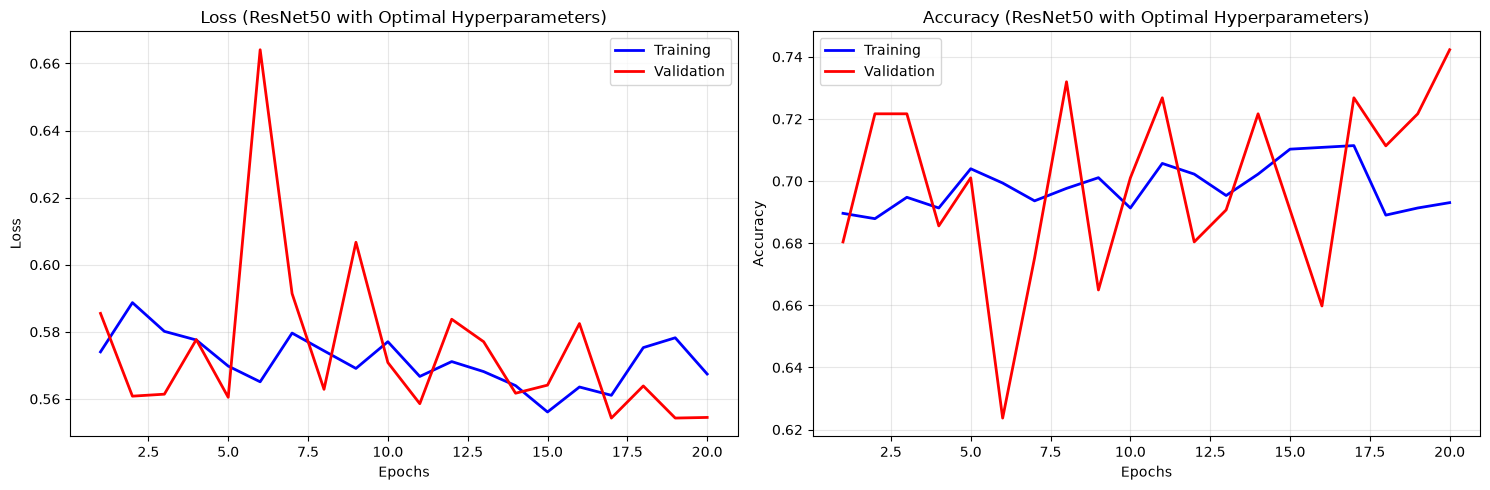


=============== ResNet50 ===============
Accuracy: 74.227%
Loss: 0.554
Precision: 77.500%
Recall/Sensitivity: 65.957%
F1-score: 71.264%
ROC-AUC: 0.7888
ResNet50 frozen: True
Trainable ResNet50 weights: 0


In [ ]:
resnet_hpCallbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="resnet50_op_hyperparameters.keras",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
    )
]

resnet_hpHistory  = (resnetFeatureModel.fit(resnetTrainDataset, validation_data=validation_dataset, epochs=20, class_weight=class_weights, callbacks=resnet_hpCallbacks))

plotTrainingHistory(resnet_hpHistory , title="ResNet50 with Optimal Hyperparameters")
resnetHP_results = printPerfMetrics(resnetFeatureModel, "ResNet50",dataset=validation_dataset, y_true=y_val_bin,)

best_hp_resnet = keras.models.load_model("resnet50_op_hyperparameters.keras")
# contains the pretrained resnet50 convolutional layers
hp_ConvLayers = best_hp_resnet.get_layer("base_resnet50")

print("ResNet50 frozen:", not hp_ConvLayers.trainable)
print("Trainable ResNet50 weights:",
      len(hp_ConvLayers.trainable_weights))

In [ ]:
# Evaluation
resnetValidationResults = printPerfMetrics(
    best_hp_resnet,
    "ResNet50 Frozen Feature Extraction + Tuned Hyperparameter - validation set",
    dataset=validation_dataset,
    y_true=y_val_bin,
)


=============== ResNet50 Frozen Feature Extraction + Tuned Hyperparameter - validation set ===============
Accuracy: 72.680%
Loss: 0.554
Precision: 75.309%
Recall/Sensitivity: 64.894%
F1-score: 69.714%
ROC-AUC: 0.7890


In [ ]:
# X_test
resnetTestResults = printPerfMetrics(
    best_hp_resnet,
    "ResNet50 Frozen Feature Extraction + Tuned Hyperparameter - Test set",
    dataset=test_dataset,
    y_true=y_test_bin,
)



=============== ResNet50 Frozen Feature Extraction + Tuned Hyperparameter - Test set ===============
Accuracy: 68.866%
Loss: 0.598
Precision: 69.856%
Recall/Sensitivity: 62.393%
F1-score: 65.914%
ROC-AUC: 0.7490



=============== ResNet50 Frozen Feature Extraction + Tuned Hyperparameter - df_test ===============
Accuracy: 64.516%
Loss: 0.616
Precision: 59.286%
Recall/Sensitivity: 61.029%
F1-score: 60.145%
ROC-AUC: 0.7174


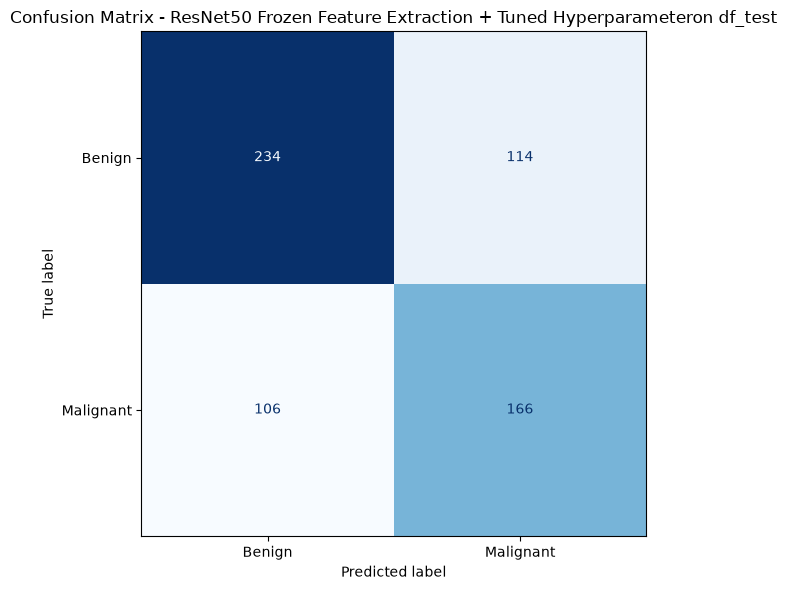

array([[234, 114],
       [106, 166]])

In [ ]:
#df_test
resnetDfTestResults = printPerfMetrics(
    best_hp_resnet,
    "ResNet50 Frozen Feature Extraction + Tuned Hyperparameter - df_test",
    dataset=dfTestDataset,
    y_true=y_df_test,
)
plotConfusionMatrix(
    y_df_test,
    resnetDfTestResults["predictions"],
    title=(
        "Confusion Matrix - ResNet50 Frozen Feature Extraction + Tuned Hyperparameter"
        "on df_test"
    ),
)

## Step 7: Building VGG16

In [171]:
def baseVGG16():
    baseVGG = keras.applications.vgg16.VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3),
        name="base_vgg16",
    )

    return baseVGG

In [172]:
vggTrainDataset = (
    tf.data.Dataset.from_tensor_slices(
        (X_train, y_train_bin)
    )
    .shuffle(
        buffer_size=len(X_train),
        seed=seed,
        reshuffle_each_iteration=True,
    )
    .batch(batchSize)
    .prefetch(tf.data.AUTOTUNE)
)

vggValidationDataset = (
    tf.data.Dataset.from_tensor_slices(
        (X_val, y_val_bin)
    )
    .batch(batchSize)
    .prefetch(tf.data.AUTOTUNE)
)

In [173]:
keras.backend.clear_session()
keras.utils.set_random_seed(seed)

vgg16Base = baseVGG16()

inputs = keras.Input(shape=(224, 224, 1))
x = data_augmentation(inputs)
x = layers.Concatenate(axis=-1)([x, x, x])
# images are currently in [0, 1]
x = layers.Rescaling(255.0)(x)
# Apply VGG16-specific preprocessing
x = vgg16_preprocess_input(x)
x = vgg16Base(x, training=False)
x = layers.Flatten()(x)
x = layers.Dense(256)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

vgg16Model = keras.Model(inputs=inputs, outputs=outputs, name="vgg16_feature_extract")

print("VGG16 trainable:", vgg16Base.trainable)

vgg16Model.summary()

vgg16Model.compile(optimizer="rmsprop",
                        loss="binary_crossentropy",
                        metrics=["accuracy"])

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
VGG16 trainable: True


Model: "vgg16_feature_extract"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mammogram_augmenta… │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 224, 224,  │          0 │ mammogram_augmen… │
│ (Concatenate)       │ 3)                │            │ mammogram_augmen… │
│                     │                   │            │ mammogram_augmen… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ concatenate[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ base_vgg16          │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 25088)     │          0 │ base_vgg16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  6,422,784 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │        257 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,137,729 (80.63 MB)

 Trainable params: 21,137,729 (80.63 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 527s 10s/step - accuracy: 0.4957 - loss: 0.6937 - val_accuracy: 0.4845 - val_loss: 0.6934
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 553s 10s/step - accuracy: 0.4699 - loss: 0.6937 - val_accuracy: 0.4845 - val_loss: 0.6932
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 379s 7s/step - accuracy: 0.4762 - loss: 0.6941 - val_accuracy: 0.5155 - val_loss: 0.6931
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 500s 9s/step - accuracy: 0.4854 - loss: 0.6942 - val_accuracy: 0.4845 - val_loss: 0.6932
Epoch 5/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 540s 10s/step - accuracy: 0.4819 - loss: 0.6939 - val_accuracy: 0.4845 - val_loss: 0.6932
Epoch 6/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 550s 10s/step - accuracy: 0.5020 - loss: 0.6939 - val_accuracy: 0.4845 - val_loss: 0.6936
Epoch 7/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 525s 10s/step - accuracy: 0.5014 - loss: 0.6937 - val_accuracy: 0.4845 - val_loss: 0.6943
Epoch 8/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 581s 10s/step - accuracy: 0.4877 - loss: 0.6934 - val_accuracy: 0.48

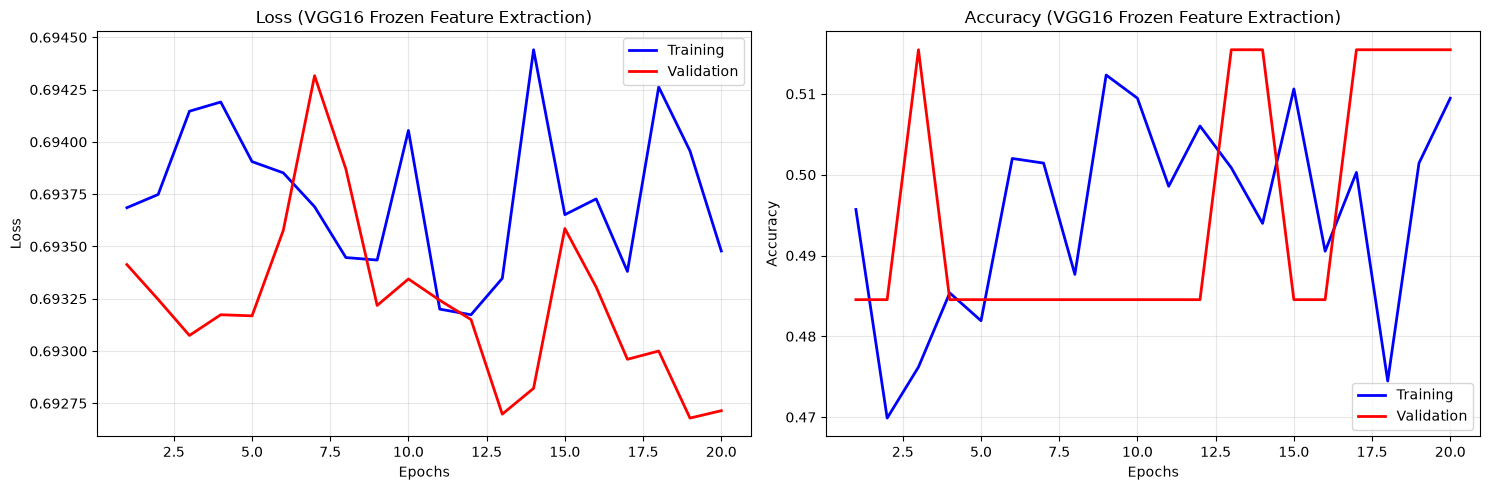

In [175]:
vgg16_callbacks= [keras.callbacks.ModelCheckpoint(filepath="vgg16_feature_extract.keras", monitor="val_loss", mode="min", save_best_only=True)]

vgg16History = vgg16Model.fit(
    vggTrainDataset,
    validation_data=vggValidationDataset,
    epochs=20,
    class_weight=class_weights,
    callbacks=vgg16_callbacks,
)

plotTrainingHistory(vgg16History, title="VGG16 Frozen Feature Extraction")

In [201]:
featureExtractionResults = printPerfMetrics(vgg16Model, "VGG16", dataset=validation_dataset, y_true=y_val_bin)


=============== VGG16 ===============
Accuracy: 51.546%
Loss: 0.693
Precision: 0.000%
Recall/Sensitivity: 0.000%
F1-score: 0.000%
ROC-AUC: 0.5000


best_base_vgg16  = complete trained classifier

frozenVggBase = internal pretrained feature extractor

In [176]:
best_base_vgg16 = keras.models.load_model("vgg16_feature_extract.keras")
frozenVggBase = best_base_vgg16.get_layer("base_vgg16")

print("VGG16 trainable:", vgg16Base.trainable)

VGG16 trainable: True


In [177]:
vggValidationResults = printPerfMetrics(best_base_vgg16, "VGG16 Frozen Feature Extraction - validation set", dataset=vggValidationDataset, y_true=y_val_bin)


=============== VGG16 Frozen Feature Extraction - validation set ===============
Accuracy: 51.546%
Loss: 0.693
Precision: 0.000%
Recall/Sensitivity: 0.000%
F1-score: 0.000%
ROC-AUC: 0.5000


In [178]:
vggTestResults = printPerfMetrics(best_base_vgg16, "VGG16 Frozen Feature Extraction - test set", dataset=test_dataset, y_true=y_test_bin)


=============== VGG16 Frozen Feature Extraction - test set ===============
Accuracy: 51.753%
Loss: 0.693
Precision: 0.000%
Recall/Sensitivity: 0.000%
F1-score: 0.000%
ROC-AUC: 0.5000



=============== VGG16 Frozen Feature Extraction - df_test ===============
Accuracy: 56.129%
Loss: 0.689
Precision: 0.000%
Recall/Sensitivity: 0.000%
F1-score: 0.000%
ROC-AUC: 0.5000


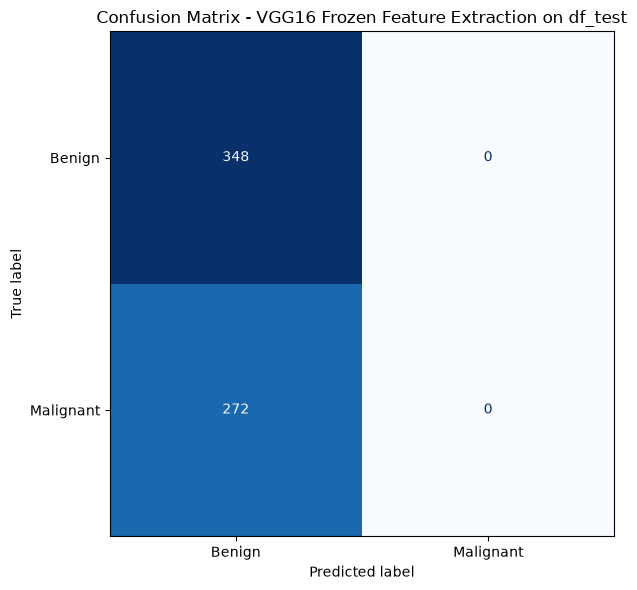

array([[348,   0],
       [272,   0]])

In [179]:
vggDfTestResults = printPerfMetrics(best_base_vgg16, "VGG16 Frozen Feature Extraction - df_test", dataset=dfTestDataset, y_true=y_df_test)
plotConfusionMatrix(y_df_test, vggDfTestResults["predictions"], 
                    title=("Confusion Matrix - VGG16 Frozen Feature Extraction on df_test"))

### VGG16 with best hyperparameters

In [180]:
inputs = keras.Input(shape=(224, 224, 1))
x = data_augmentation(inputs)
x = layers.Concatenate(axis=-1)([x, x, x])
# images are currently in [0, 1]
x = layers.Rescaling(255.0)(x)
# Apply VGG16-specific preprocessing
x = vgg16_preprocess_input(x)
x = vgg16Base(x, training=False)
x = layers.Flatten()(x)
x = layers.Dense(units=bestHp.get("dense_units"), activation="relu", kernel_regularizer=keras.regularizers.l2(bestHp.get("l2_strength")))(x)
x = layers.Dropout(bestHp.get("dropout_rate"))(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

vgg16_hpModel = keras.Model(inputs=inputs, outputs=outputs, name="vgg16_op_hyperparameters")

print("VGG16 trainable:", vgg16Base.trainable)

vgg16_hpModel.summary()

vgg16_hpModel.compile(optimizer=keras.optimizers.RMSprop(learning_rate=bestHp.get("learning_rate")), 
                      loss="binary_crossentropy",
                      metrics=["accuracy"])

VGG16 trainable: True


Model: "vgg16_op_hyperparameters"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mammogram_augmenta… │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 224, 224,  │          0 │ mammogram_augmen… │
│ (Concatenate)       │ 3)                │            │ mammogram_augmen… │
│                     │                   │            │ mammogram_augmen… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ concatenate_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ rescaling_1[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ rescaling_1[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ rescaling_1[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ base_vgg16          │ (None, 7, 7, 512) │ 14,714,688 │ add_1[0][0]       │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 25088)     │          0 │ base_vgg16[1][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │  1,605,696 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 16,320,449 (62.26 MB)

 Trainable params: 16,320,449 (62.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 262s 5s/step - accuracy: 0.4911 - loss: 0.6939 - val_accuracy: 0.5155 - val_loss: 0.6928
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 568s 10s/step - accuracy: 0.4980 - loss: 0.6939 - val_accuracy: 0.5155 - val_loss: 0.6928
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 362s 7s/step - accuracy: 0.5135 - loss: 0.6942 - val_accuracy: 0.4845 - val_loss: 0.6943
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 299s 5s/step - accuracy: 0.4951 - loss: 0.6934 - val_accuracy: 0.5155 - val_loss: 0.6929
Epoch 5/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 469s 8s/step - accuracy: 0.4980 - loss: 0.6943 - val_accuracy: 0.4845 - val_loss: 0.6935
Epoch 6/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 571s 10s/step - accuracy: 0.4991 - loss: 0.6937 - val_accuracy: 0.5155 - val_loss: 0.6929
Epoch 7/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 455s 8s/step - accuracy: 0.4814 - loss: 0.6945 - val_accuracy: 0.4845 - val_loss: 0.6932
Epoch 8/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 463s 8s/step - accuracy: 0.5009 - loss: 0.6933 - val_accuracy: 0.5155 -

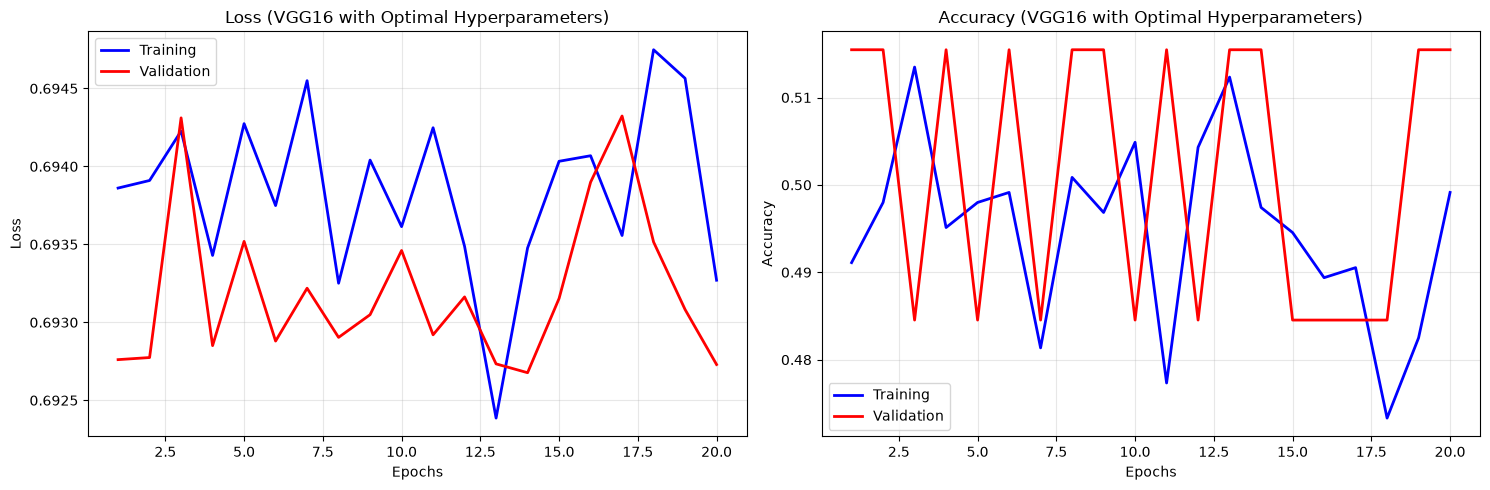

In [181]:
vgg16_hpCallbacks= [keras.callbacks.ModelCheckpoint(filepath="vgg16_op_hyperparameters.keras", monitor="val_loss", mode="min", save_best_only=True)]

vgg16_hpHistory = vgg16Model.fit(
    vggTrainDataset,
    validation_data=vggValidationDataset,
    epochs=20,
    class_weight=class_weights,
    callbacks=vgg16_hpCallbacks,
)

plotTrainingHistory(vgg16_hpHistory, title="VGG16 with Optimal Hyperparameters")

In [182]:
best_hp_vgg16 = keras.models.load_model("vgg16_op_hyperparameters.keras")
frozenVggBase = best_hp_vgg16.get_layer("base_vgg16")

print("VGG16 trainable:", vgg16Base.trainable)

VGG16 trainable: True


In [183]:
vggValidationResults = printPerfMetrics(best_hp_vgg16, "VGG16 Frozen Feature Extraction + Tuned Hyperparameter - validation set", dataset=vggValidationDataset, y_true=y_val_bin)


=============== VGG16 Frozen Feature Extraction + Tuned Hyperparameter - validation set ===============
Accuracy: 51.546%
Loss: 0.693
Precision: 0.000%
Recall/Sensitivity: 0.000%
F1-score: 0.000%
ROC-AUC: 0.5000


In [184]:
vggTestResults = printPerfMetrics(best_hp_vgg16, "VGG16 Frozen Feature Extraction + Tuned Hyperparameter - test set", dataset=test_dataset, y_true=y_test_bin)


=============== VGG16 Frozen Feature Extraction + Tuned Hyperparameter - test set ===============
Accuracy: 51.753%
Loss: 0.693
Precision: 0.000%
Recall/Sensitivity: 0.000%
F1-score: 0.000%
ROC-AUC: 0.5000



=============== VGG16 Frozen Feature Extraction + Tuned Hyperparameter - df_test ===============
Accuracy: 56.129%
Loss: 0.690
Precision: 0.000%
Recall/Sensitivity: 0.000%
F1-score: 0.000%
ROC-AUC: 0.5000


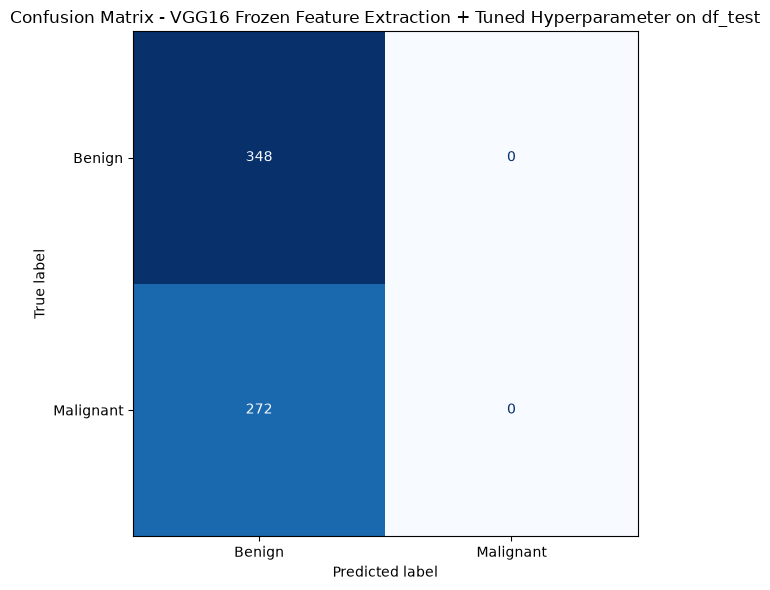

array([[348,   0],
       [272,   0]])

In [185]:
vggDfTestResults = printPerfMetrics(best_hp_vgg16, "VGG16 Frozen Feature Extraction + Tuned Hyperparameter - df_test", dataset=dfTestDataset, y_true=y_df_test)
plotConfusionMatrix(y_df_test, vggDfTestResults["predictions"], 
                    title=("Confusion Matrix - VGG16 Frozen Feature Extraction + Tuned Hyperparameter on df_test"))